# Olist Brazilian E-Commerce - complete project: cleaning, EDA, delivery-promise model
Nine tables -> ONE combined csv -> missing values & duplicates & dtypes -> imputation -> outliers -> normality -> variance & multicollinearity -> dependence, grouping & hypothesis tests.
**Part A (sections 0-6)** cleaning and statistical analysis; its output `od_model` (one clean row per delivered order) is the input of **Part B (sections B1-B10)**: target selection, leakage, feature selection, Optuna, final fit, validation.

Kaggle: add the dataset *Brazilian E-Commerce Public Dataset by Olist* (`olistbr/brazilian-ecommerce`) to the notebook; the path is detected automatically. Settings: Internet on (only for `pip install optuna` if missing).

In [1]:
import warnings, itertools
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.sparse.csgraph import connected_components
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import medcouple
from statsmodels.stats.oneway import anova_oneway
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import BayesianRidge
from sklearn.preprocessing import PowerTransformer, StandardScaler

sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 80
pd.set_option('display.max_columns', 60); pd.set_option('display.float_format', '{:,.3f}'.format)
SEED, ALPHA = 42, 0.05

## 0. Combine the nine tables into ONE csv and keep an untouched copy

In [2]:
import glob
DATA = glob.glob('/kaggle/input/**/olist_orders_dataset.csv', recursive=True)[0].rsplit('/', 1)[0] + '/' if glob.glob('/kaggle/input/**/olist_orders_dataset.csv', recursive=True) else 'olist/'   # Kaggle input or local folder
FILES = {'orders': 'orders', 'items': 'order_items', 'customers': 'customers', 'sellers': 'sellers', 'products': 'products', 'reviews': 'order_reviews', 'payments': 'order_payments',
         'geo': 'geolocation', 'category': None}
raw = {k: pd.read_csv(f'{DATA}olist_{v}_dataset.csv' if v else f'{DATA}product_category_name_translation.csv') for k, v in FILES.items()}
pd.DataFrame({k: {'rows': len(v), 'columns': v.shape[1]} for k, v in raw.items()})

,orders,items,customers,sellers,products,reviews,payments,geo,category
rows,99441,112650,99441,3095,32951,100000,103886,1000163,71
columns,8,7,5,4,9,7,5,5,2


The tables are joined on their keys into **one flat file, one row per order item** (orders without items stay, with empty item columns). Three tables have several rows per key and are reduced first:
- `geolocation` (1 M rows, many per zip prefix): rows outside Brazil are dropped, then **one centroid (median) per zip prefix**;
- `order_payments`: the main payment (largest value) per order, the total value and the number of payments;
- `order_reviews`: the latest review per order (score and dates; the free-text comments are 88 % / 58 % empty and are not carried over).

In [3]:
g = raw['geo']; inside = g.geolocation_lat.between(-34, 6) & g.geolocation_lng.between(-74, -34)
print(f'geolocation: {(~inside).sum()} rows outside Brazil dropped, {g.duplicated().sum():,} exact duplicate rows, {g.geolocation_zip_code_prefix.nunique():,} zip prefixes')
cent = g[inside].groupby('geolocation_zip_code_prefix')[['geolocation_lat', 'geolocation_lng']].median()
zip_state = g[inside].groupby('geolocation_zip_code_prefix').geolocation_state.agg(lambda s: s.mode().iloc[0])       # state the geolocation table assigns to each zip prefix
pay = raw['payments'].sort_values('payment_value', ascending=False).groupby('order_id').agg(payment_type=('payment_type', 'first'), installments=('payment_installments', 'max'), payment_total=('payment_value', 'sum'), n_payments=('payment_sequential', 'count')).reset_index()
rev = raw['reviews'].sort_values('review_answer_timestamp').drop_duplicates('order_id', keep='last')[['order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']]
flat = (raw['orders'].merge(raw['customers'], on='customer_id', how='left').merge(raw['items'], on='order_id', how='left').merge(raw['sellers'], on='seller_id', how='left')
        .merge(raw['products'], on='product_id', how='left').merge(raw['category'], on='product_category_name', how='left').merge(pay, on='order_id', how='left').merge(rev, on='order_id', how='left')
        .merge(cent.rename(columns={'geolocation_lat': 'c_lat', 'geolocation_lng': 'c_lng'}), left_on='customer_zip_code_prefix', right_index=True, how='left')
        .merge(cent.rename(columns={'geolocation_lat': 's_lat', 'geolocation_lng': 's_lng'}), left_on='seller_zip_code_prefix', right_index=True, how='left'))
print(f"combined: {flat.shape[0]:,} rows x {flat.shape[1]} columns | raw order items {len(raw['items']):,} | orders {raw['orders'].order_id.nunique():,} -> in the file {flat.order_id.nunique():,}")
assert not flat.duplicated(['order_id', 'order_item_id']).any(), 'a join multiplied rows'
for who, zc, st in [('c', 'customer_zip_code_prefix', 'customer_state'), ('s', 'seller_zip_code_prefix', 'seller_state')]:          # a centroid in another state than the address state is a wrong coordinate
    zs = flat[zc].map(zip_state); wrong = zs.notna() & (zs != flat[st]); flat.loc[wrong, [f'{who}_lat', f'{who}_lng']] = np.nan
    print(f'{who}: {int(wrong.sum())} item rows have a zip centroid in a different state than their address -> coordinate set empty (repaired in section 2)')
flat.to_csv('olist_combined.csv', index=False)

geolocation: 42 rows outside Brazil dropped, 261,831 exact duplicate rows, 19,015 zip prefixes


combined: 113,425 rows x 41 columns | raw order items 112,650 | orders 99,441 -> in the file 99,441
c: 0 item rows have a zip centroid in a different state than their address -> coordinate set empty (repaired in section 2)
s: 646 item rows have a zip centroid in a different state than their address -> coordinate set empty (repaired in section 2)


In [4]:
df_raw = pd.read_csv('olist_combined.csv')            # from here on the whole project works on this ONE file
df = df_raw.copy()                                    # all cleaning is done on df, df_raw stays untouched
print(df.shape); df.head(3).T

(113425, 41)


,0,1,2
order_id,e481f51cbdc54678b7cc49136f2d6af7,53cdb2fc8bc7dce0b6741e2150273451,47770eb9100c2d0c44946d9cf07ec65d
customer_id,9ef432eb6251297304e76186b10a928d,b0830fb4747a6c6d20dea0b8c802d7ef,41ce2a54c0b03bf3443c3d931a367089
order_status,delivered,delivered,delivered
order_purchase_timestamp,2017-10-02 10:56:33,2018-07-24 20:41:37,2018-08-08 08:38:49
order_approved_at,2017-10-02 11:07:15,2018-07-26 03:24:27,2018-08-08 08:55:23
order_delivered_carrier_date,2017-10-04 19:55:00,2018-07-26 14:31:00,2018-08-08 13:50:00
order_delivered_customer_date,2017-10-10 21:25:13,2018-08-07 15:27:45,2018-08-17 18:06:29
order_estimated_delivery_date,2017-10-18 00:00:00,2018-08-13 00:00:00,2018-09-04 00:00:00
customer_unique_id,7c396fd4830fd04220f754e42b4e5bff,af07308b275d755c9edb36a90c618231,3a653a41f6f9fc3d2a113cf8398680e8
customer_zip_code_prefix,3149,47813,75265


## 1. Missing values, duplicates, data types
### 1.1 Missing values - every type, % per column
Four kinds are checked: explicit `NaN`, empty strings, hidden placeholders and constant / empty columns.

In [5]:
PLACEHOLDERS = {'', 'na', 'n/a', 'null', 'none', '?', '-', 'unknown', 'xxxxxxxxx'}

def missing_report(d):
    text = d.select_dtypes(exclude='number').astype('string')
    hidden = text.apply(lambda s: s.str.strip().str.lower().isin(PLACEHOLDERS)).sum()
    rep = pd.DataFrame({'dtype': d.dtypes.astype(str), 'unique': d.nunique(), 'nan': d.isna().sum(), 'placeholder': hidden}).fillna(0)
    rep['missing_%'] = 100 * (rep['nan'] + rep['placeholder']) / len(d)
    rep['constant'] = rep['unique'] <= 1
    return rep.sort_values('missing_%', ascending=False)

rep = missing_report(df); rep[(rep['missing_%'] > 0) | rep['constant']]

,dtype,unique,nan,placeholder,missing_%,constant
order_delivered_customer_date,str,95664,3229,0.000,2.847,False
product_category_name_english,str,71,2402,0.000,2.118,False
product_category_name,str,73,2378,0.000,2.097,False
product_description_lenght,float64,2960,2378,0.000,2.097,False
product_name_lenght,float64,66,2378,0.000,2.097,False
product_photos_qty,float64,19,2378,0.000,2.097,False
order_delivered_carrier_date,str,81018,1968,0.000,1.735,False
s_lng,float64,2223,1674,0.000,1.476,False
s_lat,float64,2223,1674,0.000,1.476,False
product_height_cm,float64,102,793,0.000,0.699,False


In [6]:
# Is the missingness random or structural?  Delivery dates exist only for orders that got that far; product fields are missing together.
o = df.drop_duplicates('order_id')
display(pd.crosstab(o.order_status, [o.order_delivered_carrier_date.isna().rename('no carrier date'), o.order_delivered_customer_date.isna().rename('no delivery date')]))
p = df[df.product_id.notna()].drop_duplicates('product_id'); print('products without category:', p.product_category_name.isna().sum(), '| of them also missing name length / photos:', (p.product_category_name.isna() & p.product_name_lenght.isna() & p.product_photos_qty.isna()).sum())
print('delivered orders without a delivery date:', ((o.order_status == 'delivered') & o.order_delivered_customer_date.isna()).sum(), '| order rows without any item:', int(o.order_id.isin(df[df.order_item_id.isna()].order_id).sum()))

no carrier date   False       True       
no delivery date  False True  False True 
order_status                             
approved              0     0     0     2
canceled              6    69     0   550
created               0     0     0     5
delivered         96469     7     1     1
invoiced              0     0     0   314
processing            0     0     0   301
shipped               0  1107     0     0
unavailable           0     0     0   609

products without category: 610 | of them also missing name length / photos: 610
delivered orders without a delivery date: 8 | order rows without any item: 775


### 1.2 Duplicates

In [7]:
col_hash = df.apply(lambda s: hash(pd.util.hash_pandas_object(s, index=False).to_numpy().tobytes()))              # identical columns have identical hashes
print('duplicate rows:', int(df.duplicated().sum()), '| duplicate (order_id, order_item_id) keys:', int(df.duplicated(['order_id', 'order_item_id']).sum()), '| duplicated columns:', list(col_hash.index[col_hash.duplicated()]))
print('order-level columns repeat on every item row of an order: expected, they are collapsed to one row per order in 1.4')

duplicate rows: 0 | duplicate (order_id, order_item_id) keys: 0 | duplicated columns: []
order-level columns repeat on every item row of an order: expected, they are collapsed to one row per order in 1.4


In [8]:
n0 = len(df); df = df.drop_duplicates().loc[:, ~col_hash.duplicated()]; print(f'rows {n0:,} -> {len(df):,}, columns {len(col_hash)} -> {df.shape[1]}')

rows 113,425 -> 113,425, columns 41 -> 41


### 1.3 Data types
Dates arrive as text, zip prefixes as integers (they lose the leading zero and are labels, not quantities), low-cardinality text as plain strings, two column names are misspelled.

In [9]:
DATE_COLS = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'shipping_limit_date', 'review_creation_date', 'review_answer_timestamp']
ZIP_COLS = ['customer_zip_code_prefix', 'seller_zip_code_prefix']
CAT_COLS = ['order_status', 'payment_type', 'customer_state', 'seller_state']
dtypes_before = df.dtypes.astype(str)
df[DATE_COLS] = df[DATE_COLS].apply(pd.to_datetime)
for c in ZIP_COLS: df[c] = df[c].map(lambda v: f'{int(v):05d}' if pd.notna(v) else np.nan)
df[CAT_COLS] = df[CAT_COLS].astype('category'); df['order_item_id'] = df['order_item_id'].astype('Int64'); df['n_payments'] = df['n_payments'].astype('Int64')
df = df.rename(columns={'product_name_lenght': 'product_name_length', 'product_description_lenght': 'product_description_length'})
pd.DataFrame([(c, dtypes_before[c], str(df[c].dtype)) for c in dtypes_before.index if c in df and dtypes_before[c] != str(df[c].dtype)], columns=['column', 'before', 'after'])

,column,before,after
0,order_status,str,category
1,order_purchase_timestamp,str,datetime64[us]
2,order_approved_at,str,datetime64[us]
3,order_delivered_carrier_date,str,datetime64[us]
4,order_delivered_customer_date,str,datetime64[us]
5,order_estimated_delivery_date,str,datetime64[us]
6,customer_zip_code_prefix,int64,str
7,customer_state,str,category
8,order_item_id,float64,Int64
9,shipping_limit_date,str,datetime64[us]


**Findings.** The nine tables were combined into one file `olist_combined.csv` (113,425 item rows x 41 columns, 99,441 orders; no join multiplied rows). Missing values are mostly *structural*: delivery dates are empty for orders that never reached that stage (shipped 1,107, canceled 625 ...), 775 order rows have no item, 610 products lack category + name length + photos together. No placeholder text, no constant or duplicated columns, no duplicate rows or keys. Geolocation: 261,831 duplicate rows and 42 coordinates outside Brazil removed. **New check:** 646 seller item rows have a zip centroid that lies in a *different state* than the seller's address (customers: 0) - a wrong coordinate (hence wrong distance); these coordinates were emptied and are repaired in section 2. Dates were text, zip prefixes integers, status / state columns categories, two column names misspelled -> fixed.

### 1.4 One row per order
The delivery time is a property of the order, and the items of one order are not independent observations, so the item rows of `df` are collapsed into **one row per order**: product and seller facts of its items (sums, minima, means as appropriate), the customer, the main payment and the review.
Only **delivered** orders have a delivery time (other orders are structurally missing it), so the analysis table `od` contains delivered orders; the others are counted, not imputed.

In [10]:
df['volume'] = df.product_length_cm * df.product_height_cm * df.product_width_cm
df['limit_days'] = (df.shipping_limit_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
total = lambda x: x.sum(min_count=1)                                              # all-missing stays missing instead of becoming 0
order_cols = ['customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date',
              'customer_state', 'customer_zip_code_prefix', 'c_lat', 'c_lng', 'payment_type', 'installments', 'review_score']
od_all = df.sort_values('order_item_id').groupby('order_id').agg(**{c: (c, 'first') for c in order_cols}, seller_id=('seller_id', 'first'), seller_state=('seller_state', 'first'), s_lat=('s_lat', 'first'), s_lng=('s_lng', 'first'),
        category=('product_category_name_english', 'first'), n_items=('order_item_id', 'count'), n_sellers=('seller_id', 'nunique'), price=('price', 'sum'), freight=('freight_value', 'sum'),
        weight_g=('product_weight_g', total), volume=('volume', total), limit_days=('limit_days', 'min'), photos=('product_photos_qty', 'mean'),
        desc_len=('product_description_length', 'mean'), name_len=('product_name_length', 'mean')).reset_index()

ok = (od_all.order_status == 'delivered') & od_all.order_delivered_customer_date.notna() & od_all.order_delivered_carrier_date.notna()
print(od_all.order_status.value_counts().to_dict()); print(f'delivered orders with complete dates (analysis table): {ok.sum():,} of {len(od_all):,}')
od = od_all[ok].copy()
od[['customer_state', 'seller_state', 'payment_type', 'order_status']] = od[['customer_state', 'seller_state', 'payment_type', 'order_status']].astype(object)   # plain strings: different category sets cannot be compared / filled
od['days'] = (od.order_delivered_customer_date - od.order_purchase_timestamp).dt.total_seconds() / 86400            # delivery time (days)
od['est_days'] = (od.order_estimated_delivery_date - od.order_purchase_timestamp).dt.total_seconds() / 86400        # date promised at purchase
od['carrier_days'] = (od.order_delivered_carrier_date - od.order_purchase_timestamp).dt.total_seconds() / 86400
od['late'] = (od.order_delivered_customer_date > od.order_estimated_delivery_date).astype(int)
od[['price', 'freight', 'weight_g', 'volume', 'photos', 'desc_len', 'name_len', 'limit_days', 'installments', 'payment_type', 'category', 'seller_state', 'customer_state', 'c_lat', 's_lat']].isna().sum().rename('missing in the analysis table')

{'delivered': 96478, 'shipped': 1107, 'canceled': 625, 'unavailable': 609, 'invoiced': 314, 'processing': 301, 'created': 5, 'approved': 2}
delivered orders with complete dates (analysis table): 96,469 of 99,441


price                0
freight              0
weight_g            16
volume              16
photos            1332
desc_len          1332
name_len          1332
limit_days           0
installments         1
payment_type         1
category          1351
seller_state         0
customer_state       0
c_lat              265
s_lat              772
Name: missing in the analysis table, dtype: int64

## 2. Imputation
Each gap gets the method that matches its cause:
- **coordinates** of a zip prefix that is absent from the geolocation table are **repaired** with the centroid of the same state (exact structure beats any estimate);
- `weight_g == 0` is impossible and is treated as missing; a missing category / payment type becomes an explicit `'unknown'`;
- the remaining numeric product fields (weight, volume, photos, text lengths) are imputed with the **method that wins a masked benchmark**.

In [11]:
for who, st in [('c', 'customer_state'), ('s', 'seller_state')]:
    known = od[f'{who}_lat'].notna(); print(f'{who}: zip centroid known for {known.mean():.2%} of orders, repaired by state centroid: {(~known).sum()}')
    for ax in ['lat', 'lng']: od[f'{who}_{ax}'] = od[f'{who}_{ax}'].fillna(od.groupby(st)[f'{who}_{ax}'].transform('median'))
la1, lo1, la2, lo2 = [np.radians(od[c]) for c in ['c_lat', 'c_lng', 's_lat', 's_lng']]
od['dist_km'] = 2 * 6371 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))       # seller -> customer (haversine)
od[['category', 'payment_type']] = od[['category', 'payment_type']].fillna('unknown'); od.loc[od.weight_g == 0, 'weight_g'] = np.nan
print('weight_g == 0 (impossible):', int((od.weight_g.isna() & od.n_items.gt(0)).sum()), '| seller shipping deadline more than 90 days after purchase (data error, max', round(od.limit_days.max()), 'days):', int((od.limit_days > 90).sum()))
od.loc[od.limit_days > 90, 'limit_days'] = np.nan
od['info_missing'] = od.photos.isna().astype(int)                       # product page info (photos / texts) absent: keep that fact as a feature, the values are imputed below
IMP_COLS = ['price', 'freight', 'weight_g', 'volume', 'photos', 'desc_len', 'name_len', 'limit_days']
od[IMP_COLS + ['dist_km']].isna().sum().rename('gaps left')

c: zip centroid known for 99.73% of orders, repaired by state centroid: 265
s: zip centroid known for 99.20% of orders, repaired by state centroid: 772
weight_g == 0 (impossible): 22 | seller shipping deadline more than 90 days after purchase (data error, max 1052 days): 3


price            0
freight          0
weight_g        22
volume          16
photos        1332
desc_len      1332
name_len      1332
limit_days       3
dist_km          8
Name: gaps left, dtype: int64

10 % of every column is hidden completely at random and re-estimated; lower NRMSE (RMSE / std) is better.

In [12]:
X = od[IMP_COLS].dropna().astype(float).sample(20000, random_state=SEED)
mask = pd.DataFrame(np.random.default_rng(SEED).random(X.shape) < .10, index=X.index, columns=X.columns)
scaler = StandardScaler().fit(X.mask(mask))
imputers = {'mean': SimpleImputer(strategy='mean'), 'median': SimpleImputer(strategy='median'), 'KNN (k=5)': KNNImputer(n_neighbors=5), 'MICE': IterativeImputer(BayesianRidge(), max_iter=10, random_state=SEED)}
nrmse = {}
for name, imp in imputers.items():
    filled = pd.DataFrame(scaler.inverse_transform(imp.fit_transform(scaler.transform(X.mask(mask)))), index=X.index, columns=X.columns)
    nrmse[name] = {c: np.sqrt(((filled.loc[mask[c], c] - X.loc[mask[c], c]) ** 2).mean()) / X[c].std() for c in IMP_COLS}
nrmse = pd.DataFrame(nrmse); display(nrmse); BEST = nrmse.mean().idxmin(); print('best on average:', BEST)

,mean,median,KNN (k=5),MICE
price,0.967,0.998,0.897,0.866
freight,1.133,1.175,0.990,0.735
weight_g,1.038,1.099,0.854,0.609
volume,1.077,1.143,0.889,0.555
photos,1.009,1.023,0.950,0.991
desc_len,1.017,1.066,0.967,0.998
name_len,0.982,1.012,0.976,0.970
limit_days,0.926,0.938,0.927,0.915


best on average: MICE


In [13]:
gaps = od[IMP_COLS].isna()
sc = StandardScaler().fit(od[IMP_COLS]); full = pd.DataFrame(sc.inverse_transform(imputers[BEST].fit_transform(sc.transform(od[IMP_COLS]))), index=od.index, columns=IMP_COLS)
od[IMP_COLS] = od[IMP_COLS].fillna(full)
print(f'{BEST} imputed {int(gaps.to_numpy().sum())} cells; missing cells left in the numeric columns:', int(od[IMP_COLS + ["dist_km"]].isna().sum().sum()))

MICE imputed 4037 cells; missing cells left in the numeric columns: 8


**Findings.** Delivered orders with full dates: 96,469 of 99,441. Coordinates: 265 customer and 772 seller orders (before the state check only 213) were repaired with the state centroid. Two impossible values were treated as missing: `weight_g = 0` (22 orders) and a seller shipping deadline more than 90 days after purchase (3 orders, maximum 1,052 days - this alone made the skew of `limit_days` 118; it is now 3.6). A new column `info_missing` keeps the fact that the product page had no photos / texts (1,332 orders). Masked benchmark: **MICE** is best on average and clearly better where columns are related (volume 0.56, weight 0.61, freight 0.74 vs 1.0-1.1 for mean / median); photos / text lengths / limit_days are unpredictable (~1.0 for every method) - their imputed values are close to the mean and the missing fact is carried by `info_missing`.

## 3. Outliers
Business rules first (impossible values are errors and are removed), then three detectors: Tukey IQR (1.5), z-score (|z| > 3) and the **adjusted boxplot** (IQR fences stretched by the medcouple skewness measure, factor 3 = *extreme* values).

In [14]:
rules = {'carrier date before purchase': od.carrier_days < 0, 'delivery before carrier hand-over': od.order_delivered_customer_date < od.order_delivered_carrier_date, 'delivery before purchase': od.days < 0,
         'estimated date before purchase': od.est_days < 0, 'price <= 0': od.price <= 0, 'freight < 0': od.freight < 0}
print({k: int(v.sum()) for k, v in rules.items()})
bad = pd.concat(rules, axis=1).any(axis=1); od = od[~bad].copy(); print('impossible records removed:', int(bad.sum()), '| rows left:', len(od))

{'carrier date before purchase': 165, 'delivery before carrier hand-over': 23, 'delivery before purchase': 0, 'estimated date before purchase': 0, 'price <= 0': 0, 'freight < 0': 0}
impossible records removed: 188 | rows left: 96281


In [15]:
cont_cols = ['price', 'freight', 'weight_g', 'volume', 'dist_km', 'days', 'est_days', 'limit_days']          # continuous measurements

def adjusted_fences(s, k=3):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    mc = float(medcouple(s.sample(10000, random_state=SEED).to_numpy()))
    lo_exp, hi_exp = (-4, 3) if mc >= 0 else (-3, 4)
    return q1 - k * np.exp(lo_exp * mc) * iqr, q3 + k * np.exp(hi_exp * mc) * iqr

def outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1; lo, hi = adjusted_fences(s)
    return pd.Series({'skew': s.skew(), 'IQR 1.5 (%)': 100 * ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean(), 'z > 3 (%)': 100 * ((s - s.mean()).abs() > 3 * s.std()).mean(),
                      'adjusted k=3 (%)': 100 * ((s < lo) | (s > hi)).mean()})
od[cont_cols].apply(outlier_share).T

,skew,IQR 1.5 (%),z > 3 (%),adjusted k=3 (%)
price,9.884,7.947,1.722,1.152
freight,12.287,10.041,1.595,1.146
weight_g,6.575,14.040,1.983,0.209
volume,7.361,9.260,1.728,0.143
dist_km,1.653,7.680,1.620,0.000
days,3.834,5.077,1.630,0.132
est_days,0.904,2.513,1.033,0.197
limit_days,3.563,7.797,1.607,4.582


The extremes are real orders (a 30 kg sofa, a parcel that took 6 months), so rows are kept. The delivery time `days` is the modelling target, so the **uncapped cleaned table is saved for modelling** (`od_model`) and the extreme tail of the *features* is capped (winsorized) at the adjusted fences only for the statistical analysis below.

,values capped,%
price,1109,1.152
freight,1103,1.146
weight_g,201,0.209
volume,138,0.143
dist_km,8,0.008
days,127,0.132
est_days,190,0.197
limit_days,4412,4.582


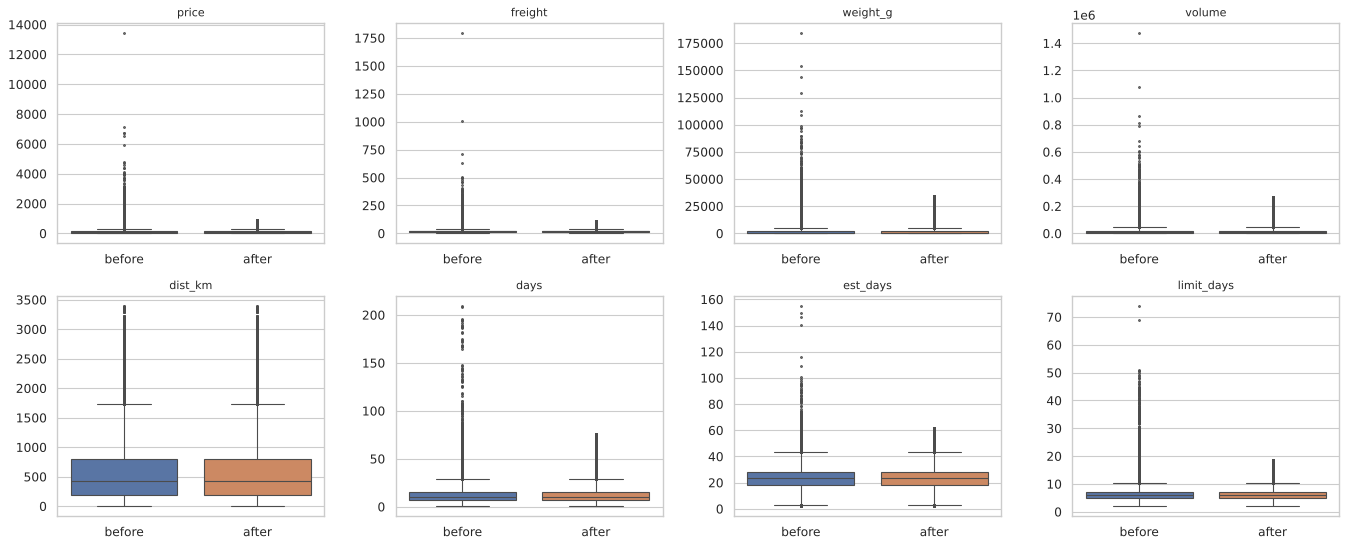

In [16]:
od_model = od.copy()
raw_c = od[cont_cols].copy()
for c in cont_cols: od[c] = od[c].clip(*adjusted_fences(od[c]))
capped = (raw_c != od[cont_cols]).sum().rename('values capped'); display(pd.concat([capped, 100 * capped / len(od)], axis=1, keys=['values capped', '%']))
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.flat, cont_cols): sns.boxplot(data=pd.DataFrame({'before': raw_c[c], 'after': od[c]}), ax=ax, fliersize=1.5); ax.set_title(c, fontsize=10)
plt.tight_layout()

**Findings.** 188 impossible records removed (165 carrier pick-up before purchase, 23 delivery before hand-over). Skew is large (price 9.9, freight 12.3); the adjusted boxplot flags far fewer points than IQR 1.5 (about 1 % vs 8 %), so only extreme values are capped (k=3). This capping is for the statistical analysis only: the model table keeps the uncapped features (tree models are insensitive to them) and the linear model gets a Yeo-Johnson transform instead. The target `days` is never capped here (see B7b).

## 4. Normality
Histogram, box-plot, Q-Q plot, skewness / excess kurtosis and the D'Agostino and Shapiro tests. With ~96k rows the tests reject normality for any real data, so the **decision rule is shape**: |skew| < 0.5 and |excess kurtosis| < 1 -> approximately normal.
Normal columns are left untouched; continuous columns that are not get a Yeo-Johnson transform (new column `<name>_norm`), kept only if it improves skew + kurtosis. Discrete columns are only reported.

In [17]:
num_cols = cont_cols + ['installments', 'n_items', 'review_score']

def normality(d):
    d = d.dropna()
    out = pd.DataFrame({'skew': d.skew(), 'ex_kurtosis': d.kurt(), 'dagostino_p': d.apply(lambda s: stats.normaltest(s)[1]),
                        'shapiro_p': d.apply(lambda s: stats.shapiro(s.sample(5000, random_state=SEED))[1])})
    out['normal'] = (out['skew'].abs() < .5) & (out['ex_kurtosis'].abs() < 1)
    return out

def plot_normality(d, cols):
    fig, axes = plt.subplots(len(cols), 3, figsize=(13, 2.4 * len(cols)))
    for (h, b, q), c in zip(axes, cols):
        s = d[c].dropna(); sns.histplot(s, kde=s.nunique() > 30, stat='density', discrete=s.nunique() <= 12, ax=h); sns.boxplot(x=s, ax=b, fliersize=1.5)
        stats.probplot(s.sample(5000, random_state=SEED), plot=q); h.set_title(c, fontsize=10); q.set_title('Q-Q plot', fontsize=9); q.get_lines()[1].set_color('tab:red'); h.set_xlabel(''); b.set_xlabel('')
    plt.tight_layout()
normality(od[num_cols])

,skew,ex_kurtosis,dagostino_p,shapiro_p,normal
price,3.083,11.221,0.000,0.000,False
freight,2.944,10.722,0.000,0.000,False
weight_g,3.760,17.608,0.000,0.000,False
volume,4.204,25.221,0.000,0.000,False
dist_km,1.653,2.501,0.000,0.000,False
days,2.223,8.076,0.000,0.000,False
est_days,0.636,1.390,0.000,0.000,False
limit_days,1.746,4.615,0.000,0.000,False
installments,1.604,2.382,0.000,0.000,False
n_items,7.569,116.781,0.000,0.000,False


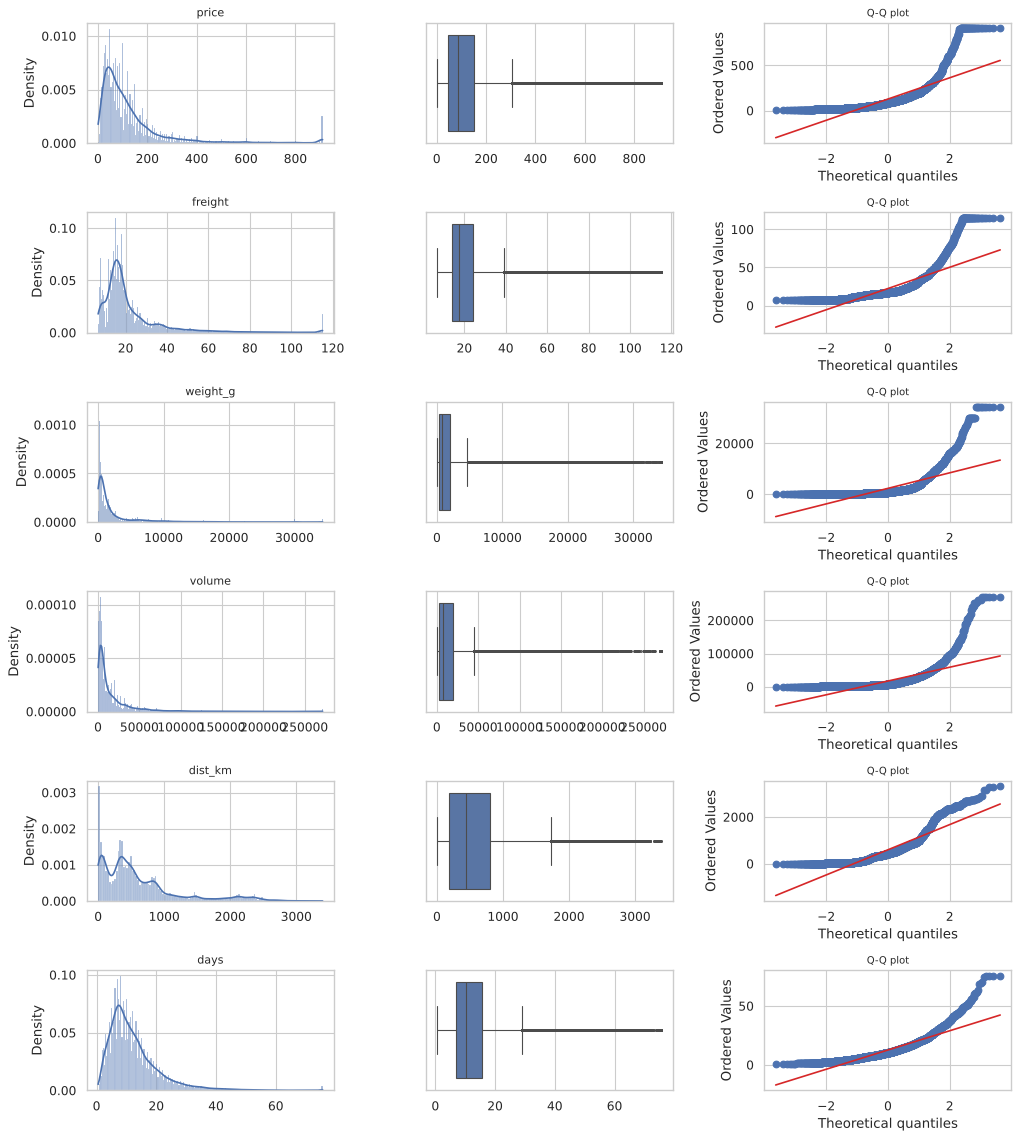

In [18]:
plot_normality(od, num_cols[:6])

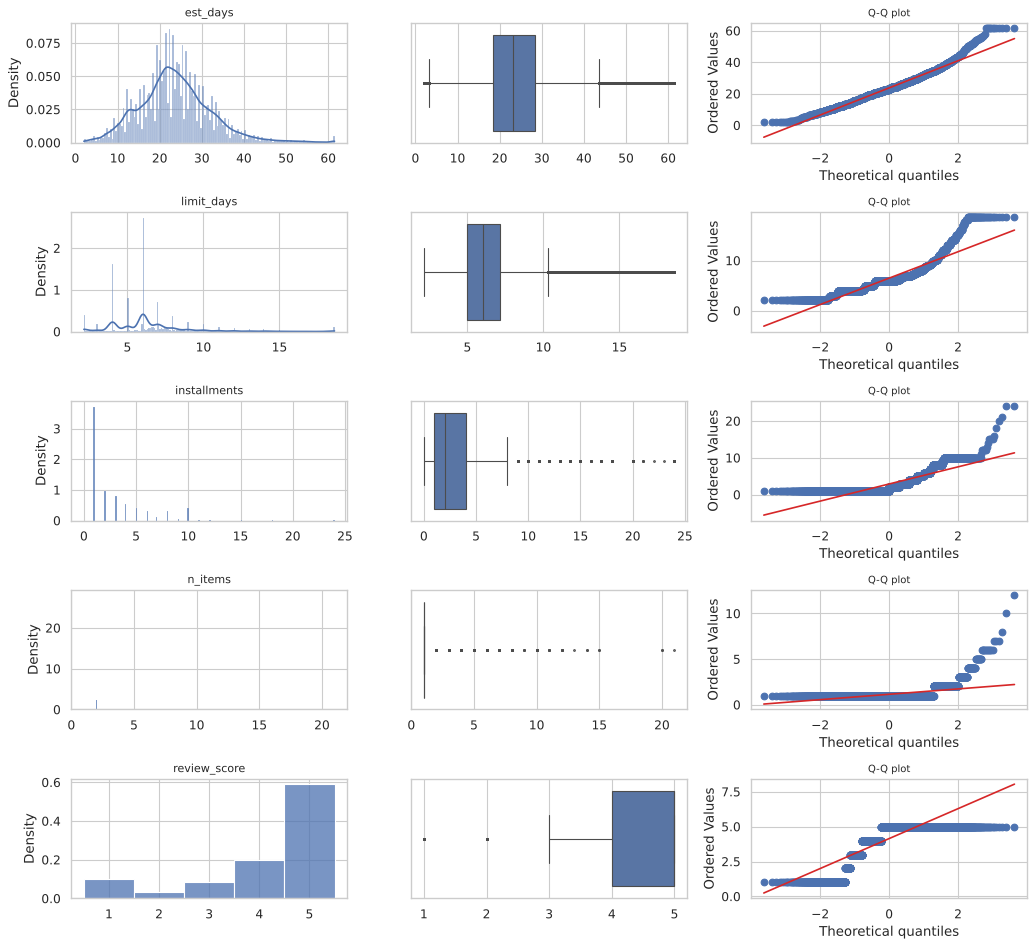

In [19]:
plot_normality(od, num_cols[6:])

,skew,ex_kurtosis,dagostino_p,shapiro_p,normal
price_norm,0.002,-0.108,0.000,0.000,True
freight_norm,0.010,-0.022,0.171,0.000,True
weight_g_norm,0.041,-0.561,0.000,0.000,True
volume_norm,0.003,-0.439,0.000,0.000,True
dist_km_norm,-0.075,-0.354,0.000,0.000,True
days_norm,0.000,0.037,0.067,0.000,True
est_days_norm,0.046,0.706,0.000,0.000,True
limit_days_norm,-0.015,0.908,0.000,0.000,True


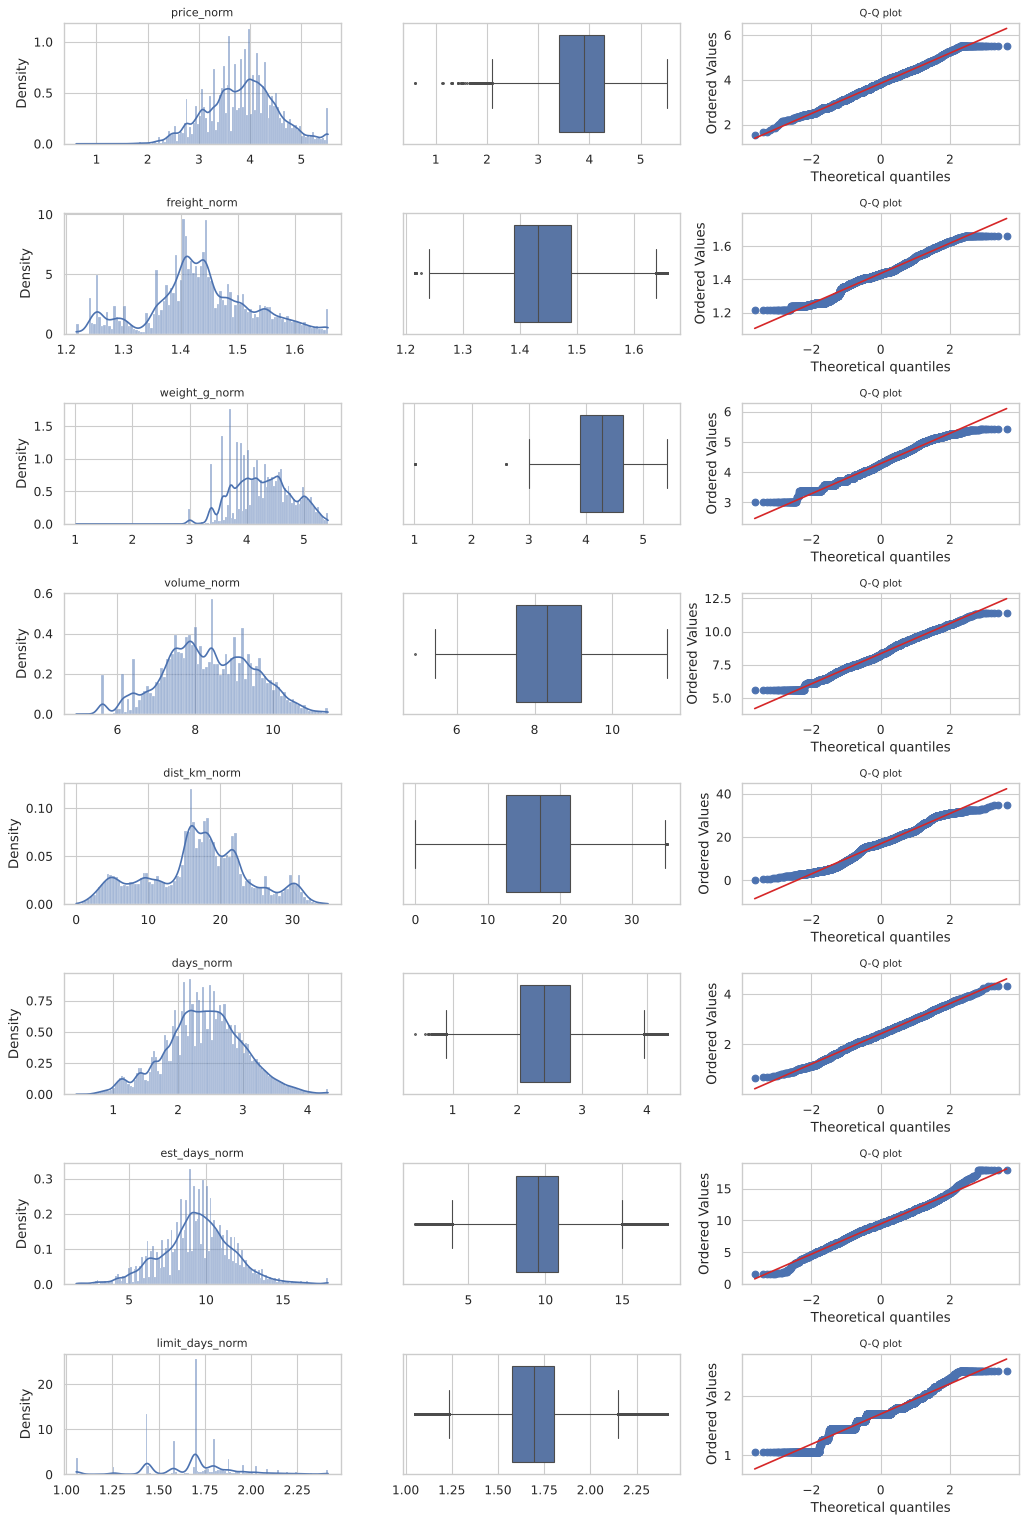

In [20]:
to_fix = [c for c in cont_cols if not normality(od[[c]]).loc[c, 'normal']]
t = pd.DataFrame(PowerTransformer(method='yeo-johnson', standardize=False).fit_transform(od[to_fix]), columns=to_fix, index=od.index)
shape = lambda d: normality(d)[['skew', 'ex_kurtosis']].abs().sum(axis=1)
improved = shape(t) < shape(od[to_fix]); norm_cols = [c + '_norm' for c in improved.index[improved]]
od[norm_cols] = t.loc[:, improved].to_numpy(); display(normality(od[norm_cols])); plot_normality(od, norm_cols)

### Box-plots of the complete dataset - numeric and categorical

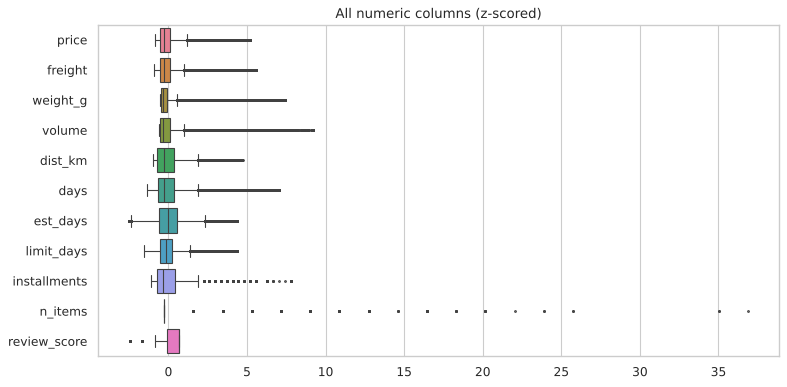

In [21]:
z = (od[num_cols] - od[num_cols].mean()) / od[num_cols].std()
plt.figure(figsize=(10, 5)); sns.boxplot(data=z, orient='h', fliersize=1.5); plt.title('All numeric columns (z-scored)'); plt.tight_layout()

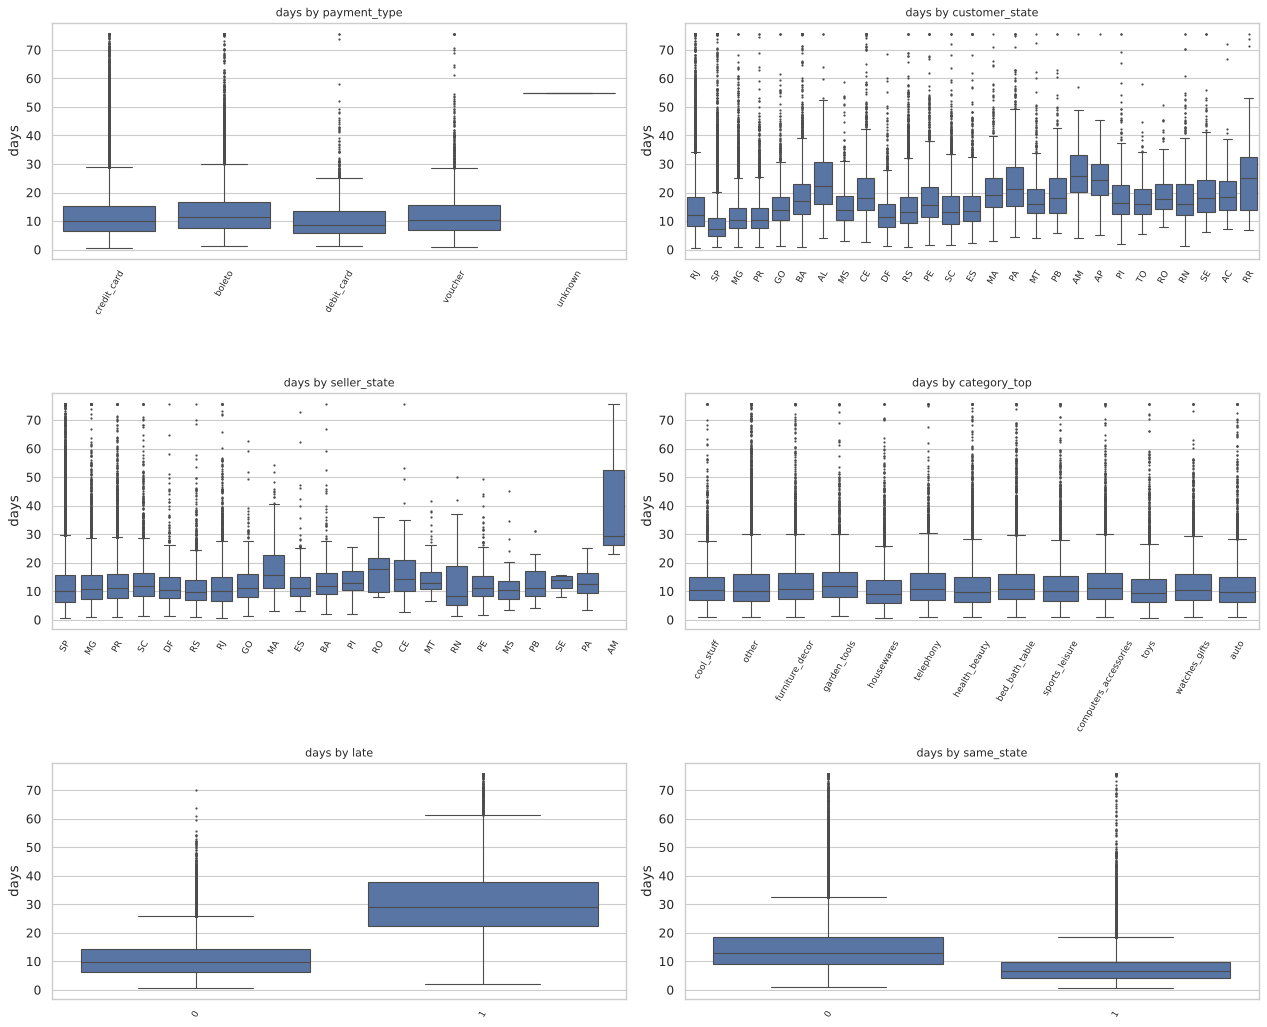

In [22]:
TARGET = 'days'
od['category_top'] = od.category.where(od.category.isin(od.category.value_counts().head(12).index), 'other')       # 12 biggest categories + other
od['same_state'] = (od.customer_state == od.seller_state).astype(int)
box_cats = ['payment_type', 'customer_state', 'seller_state', 'category_top', 'late', 'same_state']
fig, axes = plt.subplots(3, 2, figsize=(16, 13))
for ax, c in zip(axes.flat, box_cats):
    sns.boxplot(data=od, x=c, y=TARGET, ax=ax, fliersize=1); ax.set_xlabel(''); ax.set_title(f'{TARGET} by {c}', fontsize=10); ax.tick_params(axis='x', rotation=60, labelsize=8)
plt.tight_layout()

**Findings.** No continuous column is normal (all tests reject; |skew| > 0.5). Yeo-Johnson improved all 8 skewed columns (price skew 3.1 -> 0.00, days 2.2 -> 0.00), added as `_norm`. Discrete columns (installments, n_items, review_score) are only reported. Delivery time differs clearly by customer state and by same-state vs other-state in the box-plots.

## 5. Variance and multicollinearity
### 5.1 Variance
Raw variance depends on units, so the coefficient of variation and the variance after min-max scaling are shown too. **Levene's test** (median-centred) checks equal variance of the delivery time across groups.

In [23]:
nz = od[num_cols]; scaled = (nz - nz.min()) / (nz.max() - nz.min())
pd.DataFrame({'variance': nz.var(), 'CV': nz.std() / nz.mean().abs(), 'variance (min-max)': scaled.var()})

,variance,CV,variance (min-max)
price,"22,482.423",1.151,0.027
freight,279.674,0.749,0.024
weight_g,"18,399,837.577",1.828,0.016
volume,"761,092,410.635",1.608,0.010
dist_km,"350,975.273",0.987,0.030
days,80.754,0.718,0.014
est_days,74.416,0.364,0.021
limit_days,7.733,0.428,0.028
installments,7.360,0.927,0.013
n_items,0.290,0.471,0.001


In [24]:
lev = [(TARGET, g, stats.levene(*[v.values for _, v in od.groupby(g, observed=True)[TARGET]], center='median').pvalue) for g in box_cats]
pd.DataFrame(lev, columns=['measure', 'grouped by', 'levene_p']).assign(equal_variance=lambda t: t.levene_p > ALPHA)

,measure,grouped by,levene_p,equal_variance
0,days,payment_type,0.002,False
1,days,customer_state,0.000,False
2,days,seller_state,0.000,False
3,days,category_top,0.000,False
4,days,late,0.000,False
5,days,same_state,0.000,False


### 5.2 Multicollinearity - numeric
Pearson (linear) and Spearman (rank) correlation with their tests, then **VIF** (> 10 = severe): the column with the highest VIF is dropped until all are <= 10.

,var_1,var_2,pearson_r,pearson_p,spearman_rho,spearman_p
1,price,weight_g,0.413,0.000,0.535,0.000
10,freight,weight_g,0.619,0.000,0.492,0.000
11,freight,volume,0.594,0.000,0.425,0.000
12,freight,dist_km,0.381,0.000,0.582,0.000
19,weight_g,volume,0.812,0.000,0.781,0.000
34,dist_km,days,0.413,0.000,0.542,0.000
35,dist_km,est_days,0.522,0.000,0.616,0.000
40,days,est_days,0.407,0.000,0.522,0.000


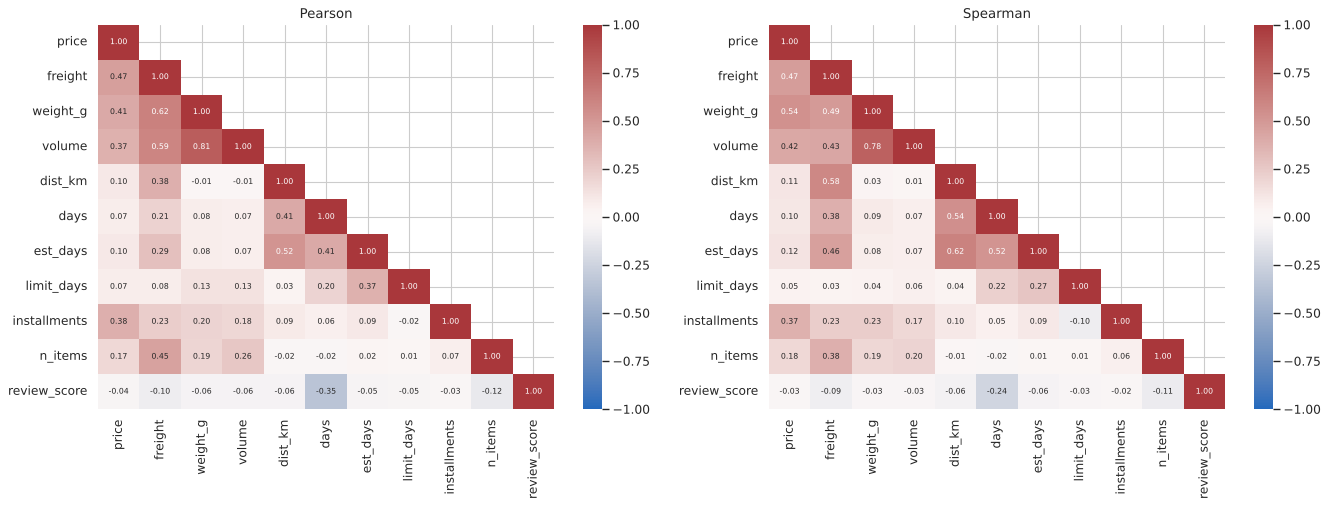

In [25]:
nn = od[num_cols].dropna()
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, method in zip(axes, ['pearson', 'spearman']):
    sns.heatmap(nn.corr(method), annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, mask=np.triu(np.ones((len(num_cols),) * 2, bool), 1), annot_kws={'size': 7}, ax=ax); ax.set_title(method.title())
plt.tight_layout()
pairs = pd.DataFrame([(a, b, *stats.pearsonr(nn[a], nn[b]), *stats.spearmanr(nn[a], nn[b])) for a, b in itertools.combinations(num_cols, 2)], columns=['var_1', 'var_2', 'pearson_r', 'pearson_p', 'spearman_rho', 'spearman_p'])
pairs[pairs[['pearson_r', 'spearman_rho']].abs().max(axis=1) > .5]

In [26]:
def vif(X):
    Z = sm.add_constant((X - X.mean()) / X.std())
    return pd.Series([variance_inflation_factor(Z.values, i) for i in range(1, Z.shape[1])], index=X.columns)

X, dropped = nn.copy(), []
vif_before = vif(X)
while (v := vif(X)).max() > 10:
    dropped.append(v.idxmax()); X = X.drop(columns=v.idxmax())
display(pd.DataFrame({'VIF before': vif_before, 'VIF after': vif(X)})); print('dropped:', dropped)

,VIF before,VIF after
price,1.465,1.465
freight,3.152,3.152
weight_g,3.496,3.496
volume,3.133,3.133
dist_km,1.938,1.938
days,1.511,1.511
est_days,1.756,1.756
limit_days,1.258,1.258
installments,1.187,1.187
n_items,1.412,1.412


dropped: []


### 5.3 Multicollinearity - categorical (Cramer's V from the chi-square test)

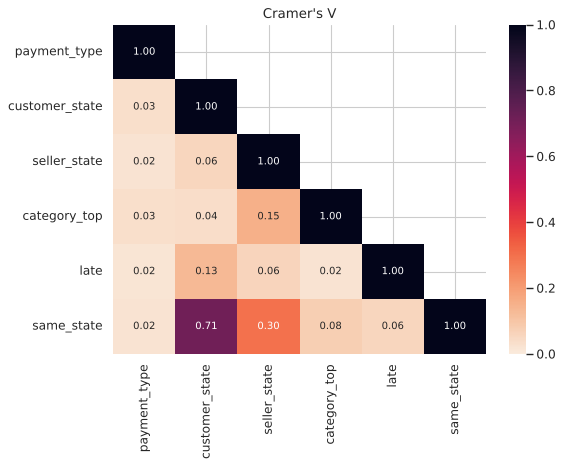

In [27]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); ct = ct.loc[ct.sum(1) > 0, ct.sum(0) > 0]
    chi2, p, _, _ = stats.chi2_contingency(ct, correction=False)
    return np.sqrt(chi2 / ct.values.sum() / (min(ct.shape) - 1)), p
V = pd.DataFrame({b: {a: cramers_v(od[a], od[b])[0] for a in box_cats} for b in box_cats})
plt.figure(figsize=(7.5, 6)); sns.heatmap(V, annot=True, fmt='.2f', cmap='rocket_r', vmin=0, vmax=1, mask=np.triu(np.ones(V.shape, bool), 1), annot_kws={'size': 9}); plt.title("Cramer's V"); plt.tight_layout()

**Findings.** Variance is unequal across every grouping (Levene p < 0.05). Strongest correlations: weight-volume 0.78-0.81, freight-weight 0.62, distance with freight / delivery days / promised days (0.54-0.62). All VIF < 3.5, so no column is dropped. Cramer's V: customer_state and same_state are strongly linked (derived from the same fields), the rest are weak.

## 6. Dependent or independent? -> grouping -> hypothesis tests
Which variables depend on each other is **not decided by hand** - it is tested:
1. one row per order (done in 1.4),
2. test **every pair** of variables for dependence,
3. **group** the variables: variables linked by a dependence form a group, variables with no link stay alone (independent),
4. inside each group compare the means and test the hypotheses.

In [28]:
# variables tested against each other (roles are NOT fixed here - the tests decide what is dependent / independent)
ORDER_CATS = ['payment_type', 'customer_state', 'seller_state', 'category_top', 'late', 'same_state']
ORDER_NUMS = ['days', 'est_days', 'price', 'freight', 'weight_g', 'volume', 'dist_km', 'limit_days', 'installments', 'n_items', 'review_score']
orders = od[ORDER_CATS + ORDER_NUMS].copy(); orders[ORDER_CATS] = orders[ORDER_CATS].astype(str); orders.shape

(96281, 17)

### 6.1 Test every pair for dependence
H0: the two variables are independent. The test follows the types of the pair:

| pair | test | strength |
|---|---|---|
| categorical - categorical | chi-square test of independence | Cramer's V |
| numeric - numeric | Spearman correlation | \|rho\| |
| numeric - categorical | **ANOVA** (normal, equal variances) / **Welch ANOVA** (normal, unequal variances) / **Kruskal-Wallis** (not normal), chosen from per-group skewness and Levene's test | sqrt(eps2), eps2 = H / (n-1) |

With ~96k orders even a tiny effect gives p < 0.05, so a pair is **dependent** only if p < 0.05 **and** strength >= 0.30 (moderate or stronger; with 0.10 all 17 variables collapsed into one group, which says nothing).

In [29]:
def compare_means(d, num, cat):
    groups = [x.values for _, x in d.groupby(cat)[num] if len(x) > 2]
    skew = max(np.nan_to_num(abs(stats.skew(a)), nan=np.inf) for a in groups)
    levene_p = stats.levene(*groups, center='median').pvalue
    h, p_kw = stats.kruskal(*groups)
    if skew < 1:
        equal = levene_p > ALPHA
        return ('ANOVA' if equal else 'Welch ANOVA'), np.sqrt(h / (len(d) - 1)), anova_oneway(groups, use_var='equal' if equal else 'unequal').pvalue
    return 'Kruskal-Wallis', np.sqrt(h / (len(d) - 1)), p_kw

def association(a, b):
    d = orders[[a, b]].dropna()
    if a in ORDER_CATS and b in ORDER_CATS: v, p = cramers_v(d[a], d[b]); return 'chi-square', v, p
    if a in ORDER_NUMS and b in ORDER_NUMS: r, p = stats.spearmanr(d[a], d[b]); return 'Spearman', abs(r), p
    return compare_means(d, *((b, a) if a in ORDER_CATS else (a, b)))

variables = ORDER_CATS + ORDER_NUMS
MIN_STRENGTH = .30
dep = pd.DataFrame([(a, b, *association(a, b)) for a, b in itertools.combinations(variables, 2)], columns=['var_1', 'var_2', 'test', 'strength', 'p_value'])
dep['conclusion'] = np.select([dep.p_value >= ALPHA, dep.strength >= MIN_STRENGTH], ['independent', 'dependent'], 'significant but negligible')
display(dep.conclusion.value_counts()); dep.sort_values('strength', ascending=False).head(40)

conclusion
significant but negligible    107
dependent                      28
independent                     1
Name: count, dtype: int64

,var_1,var_2,test,strength,p_value,conclusion
115,weight_g,volume,Spearman,0.781,0.000,dependent
76,same_state,dist_km,Kruskal-Wallis,0.763,0.000,dependent
26,customer_state,dist_km,Kruskal-Wallis,0.755,0.000,dependent
19,customer_state,same_state,chi-square,0.712,0.000,dependent
95,est_days,dist_km,Spearman,0.616,0.000,dependent
71,same_state,est_days,Kruskal-Wallis,0.587,0.000,dependent
110,freight,dist_km,Spearman,0.582,0.000,dependent
73,same_state,freight,Kruskal-Wallis,0.556,0.000,dependent
21,customer_state,est_days,Kruskal-Wallis,0.550,0.000,dependent
86,days,dist_km,Spearman,0.542,0.000,dependent


### 6.2 Grouping the variables
Every `dependent` pair is a link; variables connected by links form one group. A variable without any link is **independent** of all the others.

In [30]:
link = pd.DataFrame(0, variables, variables)
for a, b in dep.loc[dep.conclusion == 'dependent', ['var_1', 'var_2']].itertuples(index=False): link.loc[a, b] = link.loc[b, a] = 1
_, label = connected_components(link.values)
groups = pd.Series(variables).groupby(label).agg(list)
display(pd.DataFrame({'members': groups, 'size': groups.str.len(), 'role': np.where(groups.str.len() > 1, 'dependent group', 'independent variable')}))

,members,size,role
0,"[payment_type, customer_state, seller_state, c...",15,dependent group
1,[limit_days],1,independent variable
2,[review_score],1,independent variable


### 6.3 Hypothesis tests inside each group

In [31]:
group_of = pd.Series(label, index=variables)
inside = dep[dep.var_1.map(group_of) == dep.var_2.map(group_of)].assign(group=lambda t: t.var_1.map(group_of))
inside.sort_values(['group', 'strength'], ascending=[True, False])

,var_1,var_2,test,strength,p_value,conclusion,group
115,weight_g,volume,Spearman,0.781,0.000,dependent,0
76,same_state,dist_km,Kruskal-Wallis,0.763,0.000,dependent,0
26,customer_state,dist_km,Kruskal-Wallis,0.755,0.000,dependent,0
19,customer_state,same_state,chi-square,0.712,0.000,dependent,0
95,est_days,dist_km,Spearman,0.616,0.000,dependent,0
...,...,...,...,...,...,...,...
128,dist_km,n_items,Spearman,0.012,0.000,significant but negligible,0
98,est_days,n_items,Spearman,0.012,0.000,significant but negligible,0
79,same_state,n_items,Kruskal-Wallis,0.009,0.006,significant but negligible,0
67,late,installments,Kruskal-Wallis,0.009,0.007,significant but negligible,0


### 6.4 Comparison of means - numeric variables by the categorical variables of the same group

In [32]:
for gid, members in groups[groups.str.len() > 1].items():
    nums, cats = [m for m in members if m in ORDER_NUMS], [m for m in members if m in ORDER_CATS]
    print(f'---- group {gid}: means of {nums} by {cats}')
    for c in cats: display(orders.groupby(c)[nums].mean().round(2).sort_values(nums[0]).head(12))

---- group 0: means of ['days', 'est_days', 'price', 'freight', 'weight_g', 'volume', 'dist_km', 'installments', 'n_items'] by ['payment_type', 'customer_state', 'seller_state', 'category_top', 'late', 'same_state']


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
payment_type,,,,,,,,,
debit_card,10.800,21.650,110.620,20.340,"1,793.370","13,418.460",524.040,1.000,1.110
credit_card,12.310,23.700,136.110,22.500,"2,398.570","17,413.480",599.940,3.550,1.140
voucher,12.420,23.840,93.520,19.950,"1,907.240","15,142.360",591.310,1.150,1.090
boleto,13.440,23.920,115.440,22.260,"2,260.690","16,787.990",609.930,1.000,1.160
unknown,54.810,18.490,134.970,8.490,"3,000.000","12,288.000",566.040,NaN,3.000


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
customer_state,,,,,,,,,
SP,8.740,19.130,120.110,17.190,"2,292.220","17,238.150",247.630,2.680,1.150
PR,12.000,24.600,128.620,22.900,"2,251.630","16,773.160",486.000,2.930,1.150
MG,12.010,24.540,130.390,23.160,"2,435.790","16,999.980",533.040,3.050,1.140
DF,12.980,24.290,133.270,23.520,"1,929.000","14,484.020",835.040,2.770,1.130
SC,14.970,25.720,135.220,24.270,"2,399.170","17,899.700",572.780,2.920,1.150
RJ,15.260,26.340,134.460,23.600,"2,540.860","17,696.740",488.570,3.060,1.140
RS,15.280,28.490,131.330,24.450,"2,351.450","17,881.680",864.360,3.040,1.150
GO,15.510,27.090,137.670,25.620,"2,234.780","16,444.170",777.020,3.050,1.160
ES,15.620,25.550,126.050,24.150,"2,321.090","16,175.480",801.670,3.050,1.120


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
seller_state,,,,,,,,,
RS,11.490,27.060,178.950,28.300,"2,136.880","18,084.340",990.540,3.270,1.120
RJ,12.050,23.800,178.430,21.580,"1,568.970","12,185.270",585.200,3.350,1.120
SP,12.330,22.770,119.160,20.750,"2,318.740","17,654.150",541.920,2.850,1.150
MS,12.350,29.000,178.070,25.370,"2,559.260","10,215.890","1,035.150",4.020,1.040
DF,12.450,25.040,117.600,22.310,"1,186.910","10,514.010",850.600,2.740,1.100
MG,12.770,25.410,124.530,26.240,"3,048.730","16,918.190",599.420,2.950,1.120
PE,12.810,27.870,192.760,30.500,855.420,"6,413.800","1,579.590",2.720,1.110
GO,12.880,26.230,125.540,26.980,"1,212.760","10,200.270",847.110,3.090,1.130
SE,12.880,30.080,199.490,34.210,"1,627.140","10,757.570","1,629.980",5.000,1.140


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
category_top,,,,,,,,,
housewares,11.070,22.420,105.270,24.390,"3,804.380","26,996.900",491.280,2.990,1.200
toys,11.730,23.110,123.420,19.950,"1,975.600","20,175.860",564.630,2.890,1.070
health_beauty,12.080,23.350,138.050,20.210,"1,132.820","8,943.480",679.770,3.050,1.100
auto,12.230,22.810,141.890,23.290,"2,808.060","19,746.770",617.950,2.800,1.090
sports_leisure,12.230,23.390,122.710,21.470,"1,916.140","15,046.320",596.380,2.470,1.120
cool_stuff,12.320,24.100,169.080,22.990,"2,688.540","22,293.520",656.260,3.340,1.060
other,12.520,23.770,134.440,23.150,"2,974.490","20,841.580",583.630,2.840,1.120
watches_gifts,12.780,23.890,201.210,18.150,626.850,"3,070.220",646.850,3.770,1.070
telephony,12.920,23.500,74.280,16.950,283.740,"1,928.700",699.620,2.230,1.090


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
late,,,,,,,,,
0,10.890,23.870,129.500,22.190,"2,324.720","17,060.420",588.330,2.920,1.140
1,30.890,21.960,139.190,24.050,"2,594.550","18,253.460",738.150,3.010,1.110


,days,est_days,price,freight,weight_g,volume,dist_km,installments,n_items
same_state,,,,,,,,,
1,7.930,17.570,114.760,15.380,"2,350.220","17,577.470",151.190,2.650,1.150
0,15.090,27.170,139.010,26.250,"2,344.630","16,921.260",853.020,3.080,1.140


In [33]:
# categorical pair example: share of late orders by payment type, and review score by late / on time (rows add up to 1 for the first table)
display(pd.crosstab(orders['payment_type'], orders['late'], normalize='index').rename(columns={'0': 'on time', '1': 'late'}))
orders.groupby('late').review_score.agg(['mean', 'std', 'count'])

late,on time,late
payment_type,,
boleto,0.911,0.089
credit_card,0.920,0.080
debit_card,0.920,0.080
unknown,0.000,1.000
voucher,0.930,0.070


,mean,std,count
late,,,
0,4.284,1.158,88459
1,2.544,1.654,7822


In [34]:
od_model.to_csv('olist_orders_clean.csv', index=False); print('saved olist_orders_clean.csv', od_model.shape)

saved olist_orders_clean.csv (96281, 36)


**Findings.** 136 pairs tested: 28 dependent, 107 significant but negligible (large n), 1 independent. With threshold 0.30 the variables form one large dependent group (distance, same_state, customer state, promised days, freight, delivery days, weight / volume, category, payment type ...) and two independent variables: `limit_days` and `review_score`. Inside the group: delivery days are 8.7 in SP vs 15-18 in far states, 7.9 days same state vs 15.1 other states; late orders get review 2.5 vs 4.3 on time. Payment type does not change lateness (8-9 % late for every type; 'unknown' is a single order). The cleaned table `olist_orders_clean.csv` (96,281 rows) feeds the modelling notebook.

# Part B - delivery-time model
**Hub:** pulls orders from Shopify -> updates inventory in the WMS -> pushes tracking to the customer portal. **Problem solved here (the portal step):** when the order is pulled, tell the customer a **delivery date they can rely on**: a padded estimate makes the shop look slow, an optimistic one produces late parcels.
Input: `od_model` from Part A (cleaned, imputed, impossible records removed, target not capped).

In [35]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
try: import optuna
except ImportError: get_ipython().system('pip -q install optuna'); import optuna
import joblib
from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor
from scipy.stats import skew
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error, roc_auc_score, average_precision_score, balanced_accuracy_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 80
pd.set_option('display.float_format', '{:,.3f}'.format); pd.set_option('display.width', 160)
SEED = 42

## B1. Business case: what does a late parcel cost?
Customer review score by delivery outcome (delivered orders):

In [36]:
d0 = od_model.copy(); d0['late'] = d0.late.astype(bool)
d0['days_late'] = (d0.order_delivered_customer_date - d0.order_estimated_delivery_date).dt.total_seconds() / 86400
band = pd.cut(d0.days_late, [-200, -10, -3, 0, 3, 7, 200], labels=['10+ days early', '3-10 early', '0-3 early', '0-3 late', '3-7 late', '7+ late'])
display(d0.groupby(band, observed=True).review_score.agg(['mean', 'size']).rename(columns={'mean': 'avg review (1-5)', 'size': 'orders'}))
print(f'late share {d0.late.mean():.3f} | review on time {d0[~d0.late].review_score.mean():.2f} vs late {d0[d0.late].review_score.mean():.2f}')

,avg review (1-5),orders
days_late,,
10+ days early,4.313,57062
3-10 early,4.249,26662
0-3 early,4.121,4735
0-3 late,3.748,2660
3-7 late,2.296,1817
7+ late,1.722,3345


late share 0.081 | review on time 4.28 vs late 2.54


**Finding.** Only 8.1 % of delivered orders are late, but they hurt: average review 4.28 on time vs 2.54 late; 7+ days late -> 1.72. A better promise is worth building.

## B2. Features known when the order is placed
The order table is `od_model` from Part A (one row per delivered order: order, product, two locations and haversine distance, payment). Time features are added, then two kinds of **time-aware history** for the seller and for the state-to-state route: their delivery time, dispatch time and late rate **over orders already delivered before this order was placed** - exactly what the hub knows in production, so the future cannot leak.

In [37]:
orders = od_model.sort_values('order_purchase_timestamp').reset_index(drop=True)
ts = orders.order_purchase_timestamp
orders['hour'], orders['dow'], orders['month'], orders['doy'] = ts.dt.hour, ts.dt.dayofweek, ts.dt.month, ts.dt.dayofyear
orders['freight_ratio'] = orders.freight / orders.price.clip(lower=1)
orders['same_state'] = (orders.customer_state == orders.seller_state).astype(int)
print(orders.shape, '| purchases', ts.min().date(), '->', ts.max().date())

(96281, 42) | purchases 2016-09-15 -> 2018-08-29


In [38]:
def past_mean(df, key, value, known_at, k=5.0, prior=None):
    """Shrunk mean and count of `value` over earlier rows of the same `key` whose outcome was already known (known_at) at this row's purchase time."""
    now = df.order_purchase_timestamp.to_numpy(); mean, cnt = np.full(len(df), np.nan), np.zeros(len(df)); known, val = df[known_at].to_numpy(), df[value].to_numpy(float)
    keys = df[key].astype(str).to_numpy() if isinstance(key, str) else df[key].astype(str).agg('|'.join, axis=1).to_numpy()
    for kk in np.unique(keys):
        idx = np.flatnonzero(keys == kk); ordr = idx[np.argsort(known[idx])]
        tk, cs = known[ordr], np.cumsum(val[ordr])
        n = np.searchsorted(tk, now[idx], side='left')                                   # outcomes known strictly before this purchase
        s = np.where(n > 0, cs[np.maximum(n - 1, 0)], 0.0); p = 0.0 if prior is None else prior[idx]; den = n + k
        mean[idx], cnt[idx] = np.where(den > 0, (s + k * p) / np.where(den > 0, den, 1), np.nan), n
    return mean, cnt

orders['_all'] = 'all'
g_days, _ = past_mean(orders, '_all', 'days', 'order_delivered_customer_date', k=0)
g_days = np.where(np.isnan(g_days), orders.days.median(), g_days); g_carr, _ = past_mean(orders, '_all', 'carrier_days', 'order_delivered_carrier_date', k=0)
g_carr = np.where(np.isnan(g_carr), orders.carrier_days.median(), g_carr); g_late, _ = past_mean(orders, '_all', 'late', 'order_delivered_customer_date', k=0); g_late = np.where(np.isnan(g_late), .08, g_late)
orders['seller_hist_days'], orders['seller_hist_n'] = past_mean(orders, 'seller_id', 'days', 'order_delivered_customer_date', prior=g_days)
orders['seller_hist_carrier'], _ = past_mean(orders, 'seller_id', 'carrier_days', 'order_delivered_carrier_date', prior=g_carr)
orders['seller_hist_late'], _ = past_mean(orders, 'seller_id', 'late', 'order_delivered_customer_date', prior=g_late)
orders['route_hist_days'], orders['route_hist_n'] = past_mean(orders, ['seller_state', 'customer_state'], 'days', 'order_delivered_customer_date', prior=g_days)
orders['olist_est_days'] = orders.est_days
orders[['seller_hist_days', 'seller_hist_n', 'seller_hist_carrier', 'seller_hist_late', 'route_hist_days', 'route_hist_n']].describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
seller_hist_days,"96,281.000",12.257,5.337,31.826
seller_hist_n,"96,281.000",168.949,0.000,"1,784.000"
seller_hist_carrier,"96,281.000",3.253,1.142,19.577
seller_hist_late,"96,281.000",0.055,0.000,0.583
route_hist_days,"96,281.000",12.322,5.878,31.580
route_hist_n,"96,281.000","5,673.095",0.000,"30,395.000"


In [39]:
def recent_mean(df, key, value, known_at, window_days, k=5.0, prior=None):
    """Mean of `value` over rows of the same key whose outcome became known in the `window_days` before this purchase (current conditions: congestion, strikes, holidays)."""
    now = df.order_purchase_timestamp.to_numpy(); mean = np.full(len(df), np.nan); known, val = df[known_at].to_numpy(), df[value].to_numpy(float); W = np.timedelta64(int(window_days * 24 * 3600), 's')
    keys = df[key].astype(str).to_numpy() if isinstance(key, str) else df[key].astype(str).agg('|'.join, axis=1).to_numpy()
    for kk in np.unique(keys):
        idx = np.flatnonzero(keys == kk); ordr = idx[np.argsort(known[idx])]; tk = known[ordr]; cs = np.r_[0.0, np.cumsum(val[ordr])]
        hi, lo = np.searchsorted(tk, now[idx], side='left'), np.searchsorted(tk, now[idx] - W, side='left')
        n, sm = hi - lo, cs[hi] - cs[lo]; p = 0.0 if prior is None else prior[idx]; den = n + k
        mean[idx] = np.where(den > 0, (sm + k * p) / np.where(den > 0, den, 1), np.nan)
    return mean

orders['recent_all_days'] = recent_mean(orders, '_all', 'days', 'order_delivered_customer_date', 14, k=0)
orders['recent_all_late'] = recent_mean(orders, '_all', 'late', 'order_delivered_customer_date', 14, k=0)
for c in ['recent_all_days', 'recent_all_late']: orders[c] = orders[c].fillna(orders[c].median())
orders['recent_route_days'] = recent_mean(orders, ['seller_state', 'customer_state'], 'days', 'order_delivered_customer_date', 45, k=5, prior=orders.recent_all_days.to_numpy())
orders[['recent_all_days', 'recent_all_late', 'recent_route_days']].describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
recent_all_days,"96,281.000",12.641,4.693,67.955
recent_all_late,"96,281.000",0.076,0.000,0.667
recent_route_days,"96,281.000",12.342,4.693,63.854


In [40]:
# more conditions known at purchase: how slow is the destination state lately, how fast does this seller hand over lately, how many orders of this seller are waiting for the carrier
orders['recent_dest_days'] = recent_mean(orders, 'customer_state', 'days', 'order_delivered_customer_date', 21, k=5, prior=orders.recent_all_days.to_numpy())
orders['recent_seller_carrier'] = recent_mean(orders, 'seller_id', 'carrier_days', 'order_delivered_carrier_date', 60, k=3, prior=orders.seller_hist_carrier.to_numpy())
tt, hand, sid = orders.order_purchase_timestamp.to_numpy(), orders.order_delivered_carrier_date.to_numpy(), orders.seller_id.to_numpy(); backlog = np.zeros(len(orders)); D14 = np.timedelta64(14, 'D')
for s_ in np.unique(sid):
    ix = np.flatnonzero(sid == s_); placed, handed = np.sort(tt[ix]), np.sort(hand[ix])
    for i in ix:      # placed in the last 14 days minus already handed over at this purchase time
        backlog[i] = (np.searchsorted(placed, tt[i]) - np.searchsorted(placed, tt[i] - D14)) - (np.searchsorted(handed, tt[i]) - np.searchsorted(handed, tt[i] - D14))
orders['seller_backlog'] = backlog
for nm, key, w, pr in [('recent_route_14', ['seller_state', 'customer_state'], 14, 'recent_all_days'), ('recent_dest_7', 'customer_state', 7, 'recent_all_days'), ('recent_dest_45', 'customer_state', 45, 'recent_all_days'), ('recent_seller_days', 'seller_id', 60, 'seller_hist_days')]:
    orders[nm] = recent_mean(orders, key, 'days', 'order_delivered_customer_date', w, k=5, prior=orders[pr].to_numpy())          # same idea over other look-back windows / levels
orders['recent_all_30'] = recent_mean(orders, '_all', 'days', 'order_delivered_customer_date', 30, k=0); orders['recent_all_30'] = orders.recent_all_30.fillna(orders.days.median())
orders[['recent_dest_days', 'recent_seller_carrier', 'seller_backlog', 'recent_route_14', 'recent_dest_7', 'recent_dest_45', 'recent_seller_days', 'recent_all_30']].describe().T[['count', 'mean', 'min', 'max']]

,count,mean,min,max
recent_dest_days,"96,281.000",12.407,4.693,67.955
recent_seller_carrier,"96,281.000",3.165,0.582,40.825
seller_backlog,"96,281.000",0.900,-119.000,117.000
recent_route_14,"96,281.000",12.125,4.693,67.955
recent_dest_7,"96,281.000",12.170,4.693,67.955
recent_dest_45,"96,281.000",12.527,4.693,63.854
recent_seller_days,"96,281.000",12.391,4.203,62.705
recent_all_30,"96,281.000",12.693,5.984,55.835


## B3. Split with an embargo
The delivery time of an order is only known after it has been delivered, so in production you can train only on orders old enough to be finished. Training stops `EMBARGO` days before validation/test starts, with `EMBARGO` = the 99.5th percentile of delivery days (long outliers are treated in the next section). Final test = the **latest 20 %** of purchase time.

In [41]:
EMBARGO = int(np.ceil(orders.days.quantile(.995)))
cut = orders.order_purchase_timestamp.quantile(.80)
train, test = orders[orders.order_purchase_timestamp <= cut - pd.Timedelta(days=EMBARGO)].copy(), orders[orders.order_purchase_timestamp > cut].copy()
print(f'embargo {EMBARGO} days | train {len(train):,} orders through {train.order_purchase_timestamp.max():%Y-%m-%d} | test {len(test):,} orders from {test.order_purchase_timestamp.min():%Y-%m-%d} to {test.order_purchase_timestamp.max():%Y-%m-%d}')

def expanding_splits(frame, n_splits=5, min_train_fraction=.5):
    t = frame.order_purchase_timestamp; days = pd.DatetimeIndex(sorted(t.dt.normalize().unique())); d = t.dt.normalize(); first = int(len(days) * min_train_fraction); out = []
    for pos in np.array_split(np.arange(first, len(days)), n_splits):
        block = days[pos]; tr = np.flatnonzero((t <= block[0] - pd.Timedelta(days=EMBARGO)).to_numpy()); va = np.flatnonzero(d.isin(block).to_numpy())
        if len(tr) and len(va): out.append((tr, va))
    return out

def cap(idx, seed, n=20_000):
    idx = np.asarray(idx); return np.sort(np.random.default_rng(seed).choice(idx, n, replace=False)) if len(idx) > n else idx

embargo 55 days | train 64,247 orders through 2018-03-31 | test 19,256 orders from 2018-05-25 to 2018-08-29


## B4. Target selection: regression or classification?
Two framings of the same problem, compared on the **same expanding time folds of the training period** with the same candidate features (default LightGBM, 3 folds, results averaged):
- **Regression:** predict the delivery time in days; a late-risk score follows from it (`predicted days - Olist's estimated days`).
- **Classification:** predict directly whether the parcel is late (arrives after Olist's estimate; only ~8 % of orders).
Rule: choose regression if its late-risk ranking is not clearly worse (mean AUC within 0.02), because a day count answers more questions (a date to show, an interval, a late-risk) than one flag.

In [42]:
pool_cat = ['customer_state', 'seller_state', 'category', 'payment_type']
pool_num = ['dist_km', 'weight_g', 'volume', 'freight', 'price', 'freight_ratio', 'n_items', 'n_sellers', 'installments', 'limit_days', 'olist_est_days', 'photos', 'desc_len', 'name_len',
            's_lat', 's_lng', 'c_lat', 'c_lng', 'same_state', 'hour', 'dow', 'month', 'doy', 'seller_hist_days', 'seller_hist_n', 'seller_hist_carrier', 'seller_hist_late', 'route_hist_days', 'route_hist_n',
            'recent_all_days', 'recent_all_late', 'recent_route_days', 'recent_dest_days', 'recent_seller_carrier', 'seller_backlog', 'recent_route_14', 'recent_dest_7', 'recent_dest_45', 'recent_seller_days', 'recent_all_30', 'info_missing']
def as_frame(df, cols):
    X = df[cols].copy()
    for c in [c for c in cols if c in pool_cat]: X[c] = X[c].astype('category').cat.codes
    return X
Xtr_all, y_raw, late_tr, est_tr = as_frame(train, pool_cat + pool_num), train.days.to_numpy(), train.late.to_numpy(), train.est_days.to_numpy()
rows = []
for i, (tr, va) in enumerate(expanding_splits(train, 3)):
    tr = cap(tr, SEED + i, 20_000)
    reg = LGBMRegressor(n_estimators=250, learning_rate=.05, num_leaves=31, verbose=-1, n_jobs=2, random_state=SEED).fit(Xtr_all.iloc[tr], np.log1p(np.minimum(y_raw[tr], 60)))
    clf = LGBMClassifier(n_estimators=250, learning_rate=.05, num_leaves=31, verbose=-1, n_jobs=2, random_state=SEED).fit(Xtr_all.iloc[tr], late_tr[tr])
    pr, pc = np.expm1(reg.predict(Xtr_all.iloc[va])), clf.predict_proba(Xtr_all.iloc[va])[:, 1]; yl = late_tr[va]
    rows.append({'regression -> late AUC': roc_auc_score(yl, pr - est_tr[va]), 'classifier late AUC': roc_auc_score(yl, pc), "Olist's estimate late AUC": roc_auc_score(yl, -est_tr[va]),
                 'regression -> late PR-AUC': average_precision_score(yl, pr - est_tr[va]), 'classifier late PR-AUC': average_precision_score(yl, pc), 'late rate': yl.mean(),
                 'regression MAE (days)': mean_absolute_error(y_raw[va], pr), "Olist's estimate MAE (days)": mean_absolute_error(y_raw[va], est_tr[va])})
comp = pd.DataFrame(rows, index=[f'fold {i + 1}' for i in range(len(rows))]); comp.loc['mean'] = comp.mean(); display(comp)
REGRESSION = comp.loc['mean', 'regression -> late AUC'] >= comp.loc['mean', 'classifier late AUC'] - 0.02
print('TECHNIQUE:', 'regression on delivery days (late-risk derived from it)' if REGRESSION else 'classification')

,regression -> late AUC,classifier late AUC,Olist's estimate late AUC,regression -> late PR-AUC,classifier late PR-AUC,late rate,regression MAE (days),Olist's estimate MAE (days)
fold 1,0.667,0.677,0.540,0.112,0.110,0.047,3.930,12.106
fold 2,0.634,0.579,0.507,0.176,0.123,0.103,5.922,12.287
fold 3,0.630,0.612,0.509,0.231,0.211,0.162,6.816,11.173
mean,0.644,0.623,0.519,0.173,0.148,0.104,5.556,11.856


TECHNIQUE: regression on delivery days (late-risk derived from it)


**Decision: regression.** Across 3 forward folds the regression's late-AUC (0.644) is not worse than a dedicated classifier (0.623) and its PR-AUC is higher (0.173 vs 0.148); regression also gives a delivery date with an interval. Regression MAE 5.6 days vs 11.9 for Olist's own estimate. From here on only regression is used.

## B5. Leakage
A feature is allowed only if it is **known when the order is placed**. Check: (a) leakage by definition, (b) a detector - how much of the target does one column explain alone on later data (single-column decision tree, forward-time split).

In [43]:
audit = orders.assign(approval_lag=(orders.order_approved_at - orders.order_purchase_timestamp).dt.total_seconds() / 86400,
                      delivered_ts=orders.order_delivered_customer_date.astype('int64') / 1e9, carrier_ts=orders.order_delivered_carrier_date.astype('int64') / 1e9,
                      review_score=orders.review_score)
cols = ['carrier_days', 'delivered_ts', 'carrier_ts', 'late', 'approval_lag', 'review_score'] + pool_num + pool_cat
Xa = as_frame(audit, [c for c in cols if c in pool_cat + pool_num]).join(audit[['carrier_days', 'delivered_ts', 'carrier_ts', 'late', 'approval_lag', 'review_score']])
Xa = Xa.fillna(Xa.median())
tr_, va_ = expanding_splits(train, 3)[-1]; Xa = Xa.loc[train.index].reset_index(drop=True); y_a = train.days.to_numpy()
res = {c: r2_score(y_a[va_], DecisionTreeRegressor(max_depth=6, min_samples_leaf=50, random_state=SEED).fit(Xa.loc[cap(tr_, SEED, 20_000), [c]], y_a[cap(tr_, SEED, 20_000)]).predict(Xa.loc[va_, [c]])) for c in Xa.columns}
display(pd.Series(res, name='R2 of one column alone (later orders)').sort_values(ascending=False).head(12))

late                0.463
recent_route_14     0.181
recent_dest_45      0.172
recent_route_days   0.166
recent_dest_days    0.158
recent_dest_7       0.155
route_hist_days     0.116
review_score        0.085
dist_km             0.045
customer_state      0.033
same_state          0.026
olist_est_days      0.016
Name: R2 of one column alone (later orders), dtype: float64

In [44]:
LEAKY = {'order_delivered_customer_date': 'is the outcome (target = this - purchase)', 'order_delivered_carrier_date': 'hand-over to the carrier happens after the order is placed',
         'carrier_days': 'derived from the carrier date', 'order_status': 'only "delivered" orders have a time; status changes later', 'late': 'defined from the target',
         'order_approved_at': 'approval time (boleto: days later) is not known at order time', 'review_score / review dates': 'written after delivery', 'order_estimated_delivery_date': 'known at purchase: kept as a feature (olist_est_days)'}
pd.Series(LEAKY, name='why')

order_delivered_customer_date            is the outcome (target = this - purchase)
order_delivered_carrier_date     hand-over to the carrier happens after the ord...
carrier_days                                         derived from the carrier date
order_status                     only "delivered" orders have a time; status ch...
late                                                       defined from the target
order_approved_at                approval time (boleto: days later) is not know...
review_score / review dates                                 written after delivery
order_estimated_delivery_date    known at purchase: kept as a feature (olist_es...
Name: why, dtype: str

**Leakage.** Delivery date, carrier hand-over, status, `late`, approval time and review are only known after the order -> excluded. The detector confirms it: `late` alone explains 46 % of variance, `review_score` 8.5 %, `carrier_days` is flagged. History features (`recent_route_14`, `recent_dest_45`, `recent_route_days`, `recent_dest_*`, `route_hist_days`) explain 12-18 % alone but use only orders delivered *before* the purchase (checked by construction: outcome timestamp < purchase timestamp), so they are allowed. Training stops 55 days before the test period (embargo), so no training order's outcome overlaps the test period.

## B6. Target skewness and noise
Delivery time is right-skewed with a long tail (parcels lost or stuck for weeks). Two corrections, both decided by a rule and fitted on the **training period only**: (1) **tail noise**: training targets are winsorised at the 99.5th percentile (evaluation always uses the raw target); (2) **skewness**: if skew > 0.5 the model is trained on `log1p(days)` and predictions are back-transformed.

skew raw 3.91 | winsorised at 57.3 days (affects 0.50% of orders) -> skew 1.77 | log1p skew -0.08 | log-transform used: True


noise check: share of variance explained by Olist's own estimate (R2 of days ~ est_days): 0.127


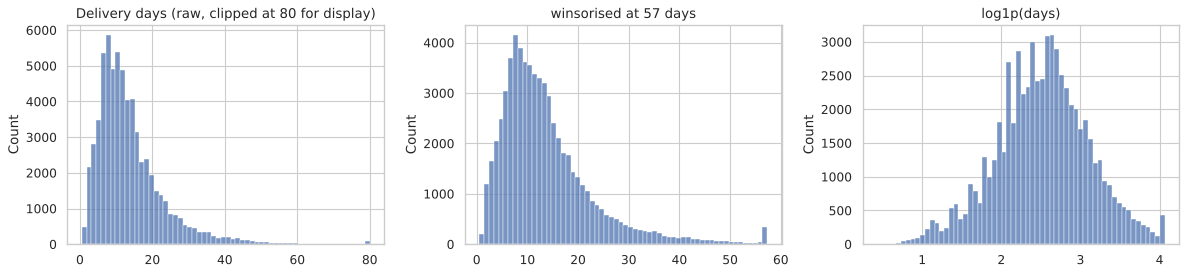

In [45]:
y_tr = train.days.to_numpy(); CAP = float(np.quantile(y_tr, .995)); y_w = np.minimum(y_tr, CAP)
SKEWED = skew(y_w) > .5
print(f'skew raw {skew(y_tr):.2f} | winsorised at {CAP:.1f} days (affects {np.mean(y_tr > CAP):.2%} of orders) -> skew {skew(y_w):.2f} | log1p skew {skew(np.log1p(y_w)):.2f} | log-transform used: {SKEWED}')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(y_tr.clip(max=80), bins=60, ax=ax[0]).set(title='Delivery days (raw, clipped at 80 for display)'); sns.histplot(y_w, bins=60, ax=ax[1]).set(title=f'winsorised at {CAP:.0f} days')
sns.histplot(np.log1p(y_w), bins=60, ax=ax[2]).set(title='log1p(days)'); plt.tight_layout()
print('noise check: share of variance explained by Olist\'s own estimate (R2 of days ~ est_days):', round(r2_score(y_tr, LinearRegression().fit(train[['est_days']], y_tr).predict(train[['est_days']])), 3))

**Skew and noise.** Delivery days skew 3.91; log1p brings it to -0.08, so the models learn `log1p(days)` and predict back with expm1. Noise: Olist's own estimate explains only 12.7 % of the variance of the real time. The winsorising level is decided in B7b.

## B7. Feature selection
Candidates: all order-time columns (29 numeric, 4 categorical). **Greedy forward selection** on temporal folds of the training period: a feature is added only if its MAE gain is positive and beats the best of **three random probe columns** (a feature must do better than pure noise). An earlier, stricter rule (extra margin of 0.01 days) stopped after 6 features and was worse in forward cross-validation (see below), so the margin was dropped.

In [46]:
rng = np.random.default_rng(SEED)
pool = as_frame(train, pool_cat + pool_num).assign(probe_num=rng.normal(size=len(train)), probe_int=rng.integers(0, 24, len(train)).astype(float))
pool['probe_noise2'] = rng.normal(size=len(pool)); probes = ['probe_num', 'probe_int', 'probe_noise2']; sel_cv = expanding_splits(train, 3); yt = np.log1p(y_w)
def cv_mae(cols):
    errs = []
    for i, (tr, va) in enumerate(sel_cv):
        tr = cap(tr, SEED + i, 10_000)
        m = LGBMRegressor(n_estimators=120, learning_rate=.08, num_leaves=15, min_child_samples=40, verbose=-1, n_jobs=2, random_state=SEED).fit(pool.iloc[tr][cols], yt[tr])
        errs.append(mean_absolute_error(y_tr[va], np.expm1(m.predict(pool.iloc[va][cols]))))
    return float(np.mean(errs))
base = np.mean([mean_absolute_error(y_tr[va], np.full(len(va), np.median(y_tr[tr]))) for tr, va in sel_cv])
FEATURES, current, trace = [], base, []
while len(FEATURES) < 15:
    gain = pd.Series({c: current - cv_mae(FEATURES + [c]) for c in pool.columns if c not in FEATURES})
    top = gain.drop(probes, errors='ignore').idxmax()
    ok = gain[top] > max(gain[probes].max(), 0)
    trace.append({'candidate': top, 'MAE gain (days)': gain[top], 'best probe gain': gain[probes].max(), 'accepted': ok})
    if not ok: break
    FEATURES.append(top); current -= gain[top]
display(pd.DataFrame(trace)); print(f'baseline MAE (median predictor) {base:.3f} -> {current:.3f} days | selected {len(FEATURES)}:', FEATURES)

,candidate,MAE gain (days),best probe gain,accepted
0,recent_route_days,1.096,-0.033,True
1,olist_est_days,0.171,-0.008,True
2,s_lat,0.100,-0.000,True
3,recent_seller_carrier,0.062,-0.001,True
4,limit_days,0.025,-0.002,True
5,same_state,0.032,-0.001,True
6,freight,0.014,-0.006,True
7,recent_dest_days,0.018,-0.004,True
8,dow,0.011,-0.005,True
9,n_sellers,0.007,-0.001,True


baseline MAE (median predictor) 6.895 -> 5.332 days | selected 15: ['recent_route_days', 'olist_est_days', 's_lat', 'recent_seller_carrier', 'limit_days', 'same_state', 'freight', 'recent_dest_days', 'dow', 'n_sellers', 'seller_backlog', 'weight_g', 'payment_type', 'hour', 'n_items']


**Selected features (15, the round limit).** With the stricter rule (extra 0.01-day margin) selection stopped after 6 features and was worse in forward-CV; with the plain rule (beat the best of 3 probes) it keeps adding small gains: recent_route_days (1.10 days), olist_est_days, s_lat, recent_seller_carrier, limit_days, same_state, freight, recent_dest_days, dow, n_sellers, seller_backlog, weight_g, payment_type, hour, n_items. Median predictor MAE 6.90 -> 5.33. Several late additions gain only 0.001-0.01 days.

### B7b. Tail noise - how hard to winsorise the training target?
Extreme delivery times (64 orders took > 100 days, 306 > 60) are mostly lost / stuck parcels that no order-time information can predict. The winsorising level is therefore **chosen by forward cross-validation on the training period** (never on the test set), scoring the raw target.

In [47]:
cv5 = expanding_splits(train, 5); rows = []
for q in [.90, .95, .98, .995, 1.0]:
    P_, ok_ = np.zeros(len(train)), np.zeros(len(train), bool)
    for tr, va in cv5:
        tr = cap(tr, SEED, 30_000); c_ = np.quantile(y_tr[tr], q)
        P_[va] = np.expm1(LGBMRegressor(n_estimators=400, learning_rate=.04, num_leaves=15, min_child_samples=80, subsample=.8, subsample_freq=1, colsample_bytree=.7, reg_lambda=5, verbose=-1, n_jobs=4, random_state=SEED).fit(pool.iloc[tr][FEATURES], np.log1p(np.minimum(y_tr[tr], c_))).predict(pool.iloc[va][FEATURES])); ok_[va] = True
    rows.append({'winsorise at quantile': q, 'forward-CV MAE (days)': mean_absolute_error(y_tr[ok_], P_[ok_]), 'forward-CV R2': r2_score(y_tr[ok_], P_[ok_])})
cap_tab = pd.DataFrame(rows).set_index('winsorise at quantile'); display(cap_tab)
Q_CAP = float(cap_tab['forward-CV MAE (days)'].idxmin()); CAP = float(np.quantile(y_tr, Q_CAP)); y_w = np.minimum(y_tr, CAP); SKEWED = skew(y_w) > .5
print(f'chosen: winsorise at the {Q_CAP:.3f} quantile = {CAP:.1f} days | skew after {skew(y_w):.2f} | log-transform used: {SKEWED}')

,forward-CV MAE (days),forward-CV R2
winsorise at quantile,,
0.900,5.614,0.161
0.950,5.545,0.188
0.980,5.511,0.204
0.995,5.506,0.208
1.000,5.502,0.211


chosen: winsorise at the 1.000 quantile = 209.6 days | skew after 3.91 | log-transform used: True


**Tail noise.** Winsorising the training target does not help: forward-CV MAE is 5.614 / 5.545 / 5.511 / 5.506 / 5.502 for the 0.90 / 0.95 / 0.98 / 0.995 / 1.0 quantile (R2 0.161 -> 0.211). The tail is therefore kept (the log transform already tames it) - a harder cut only removes information. Chosen by cross-validation on the training period, not on the test set.

## B8. Model search with Optuna and temporal cross-validation
**Phase 1:** five model families, 50 Optuna (TPE) trials each: ElasticNet, RandomForest, HistGradientBoosting, LightGBM, XGBoost. A trial is scored by 5-fold expanding-window CV (with the embargo) on **MAE in days** (the error a customer actually feels; robust to the long tail). Preprocessing is inside every fold; training rows are capped at 20,000 per fold to keep the search affordable.
**Phase 2:** the best family gets 100 more trials. The test period is not touched until the final evaluation.

In [48]:
X_train = train[FEATURES]; cv = expanding_splits(train, 5)
for i, (tr, va) in enumerate(cv, 1): print(f'fold {i}: train {len(tr):>6,} (through {train.order_purchase_timestamp.iloc[tr].max():%Y-%m-%d}) | validate {len(va):>6,} ({train.order_purchase_timestamp.iloc[va].min():%Y-%m-%d} -> {train.order_purchase_timestamp.iloc[va].max():%Y-%m-%d})')
cat_f, num_f = [c for c in FEATURES if c in pool_cat], [c for c in FEATURES if c in pool_num]

def preprocess(kind):
    if kind == 'linear':
        return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50), cat_f), ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('pt', PowerTransformer()), ('sc', StandardScaler())]), num_f)])          # Yeo-Johnson: the inputs are strongly skewed
    num = SimpleImputer(strategy='median') if kind == 'forest' else 'passthrough'           # boosting models handle missing values natively
    return ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_f), ('num', num, num_f)])

def build(name, t):
    if name == 'ElasticNet': m, kind = ElasticNet(alpha=t.suggest_float('alpha', 1e-4, 1, log=True), l1_ratio=t.suggest_float('l1_ratio', 0, 1), max_iter=5000), 'linear'
    elif name == 'RandomForest': m, kind = RandomForestRegressor(n_estimators=t.suggest_int('n_estimators', 50, 100), max_depth=t.suggest_int('max_depth', 4, 14), min_samples_leaf=t.suggest_int('min_samples_leaf', 3, 50, log=True), max_features=t.suggest_float('max_features', .3, 1), n_jobs=2, random_state=SEED), 'forest'
    elif name == 'HistGradientBoosting': m, kind = HistGradientBoostingRegressor(learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), max_iter=t.suggest_int('max_iter', 100, 400), max_leaf_nodes=t.suggest_int('max_leaf_nodes', 8, 64), min_samples_leaf=t.suggest_int('min_samples_leaf', 5, 200, log=True), l2_regularization=t.suggest_float('l2_regularization', 1e-3, 10, log=True), loss=t.suggest_categorical('loss', ['squared_error', 'absolute_error']), random_state=SEED), 'boost'
    elif name == 'LightGBM': m, kind = LGBMRegressor(objective=t.suggest_categorical('loss', ['regression', 'l1', 'huber']), n_estimators=t.suggest_int('n_estimators', 100, 600), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), num_leaves=t.suggest_int('num_leaves', 8, 64), min_child_samples=t.suggest_int('min_child_samples', 5, 200, log=True), subsample=t.suggest_float('subsample', .5, 1), subsample_freq=1, colsample_bytree=t.suggest_float('colsample_bytree', .5, 1), reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), verbose=-1, n_jobs=2, random_state=SEED), 'boost'
    else: m, kind = XGBRegressor(objective=t.suggest_categorical('loss', ['reg:squarederror', 'reg:absoluteerror']), n_estimators=t.suggest_int('n_estimators', 100, 500), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), max_depth=t.suggest_int('max_depth', 3, 8), min_child_weight=t.suggest_float('min_child_weight', 1, 100, log=True), subsample=t.suggest_float('subsample', .5, 1), colsample_bytree=t.suggest_float('colsample_bytree', .5, 1), reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), tree_method='hist', n_jobs=2, random_state=SEED), 'boost'
    pipe = Pipeline([('prep', preprocess(kind)), ('model', m)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1) if SKEWED else pipe

def run_cv(make):
    oof, fold = np.full(len(train), np.nan), []
    for i, (tr, va) in enumerate(cv):
        tr = cap(tr, SEED + i); m = make().fit(X_train.iloc[tr], y_w[tr]); p = np.clip(m.predict(X_train.iloc[va]), 0, None); oof[va] = p; fold.append(mean_absolute_error(y_tr[va], p))
    return oof, np.array(fold)

def objective(t, name):
    _, fl = run_cv(lambda: build(name, t)); t.set_user_attr('fold_std', float(fl.std(ddof=1))); return float(fl.mean())
MODELS = ['ElasticNet', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'XGBoost']; N_TRIALS, N_TRIALS_BEST = 50, 100

fold 1: train 13,027 (through 2017-06-18) | validate  6,497 (2017-08-13 -> 2017-09-28)
fold 2: train 18,643 (through 2017-08-04) | validate  6,662 (2017-09-29 -> 2017-11-13)
fold 3: train 24,962 (through 2017-09-19) | validate 10,663 (2017-11-14 -> 2017-12-29)
fold 4: train 31,337 (through 2017-11-04) | validate 10,028 (2017-12-30 -> 2018-02-13)
fold 5: train 42,406 (through 2017-12-20) | validate 10,717 (2018-02-14 -> 2018-03-31)


### Phase 1 - five models x 50 trials

In [49]:
studies = {}
for name in MODELS:
    studies[name] = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studies[name].optimize(lambda t: objective(t, name), n_trials=N_TRIALS)
    print(f'{name:<22} best CV MAE {studies[name].best_value:.4f} days')
base_cv = np.mean([mean_absolute_error(y_tr[va], np.full(len(va), np.median(y_tr[tr]))) for tr, va in cv])
phase1 = pd.DataFrame({n: {'best CV MAE (days)': s.best_value, 'fold std': s.best_trial.user_attrs['fold_std'], 'trials': len(s.trials), 'minutes': sum(t.duration.total_seconds() for t in s.trials) / 60} for n, s in studies.items()}).T
phase1.loc['median predictor (reference)'] = [base_cv, np.nan, 0, 0]; display(phase1.sort_values('best CV MAE (days)'))

ElasticNet             best CV MAE 5.3294 days


RandomForest           best CV MAE 5.2978 days


HistGradientBoosting   best CV MAE 5.2540 days


LightGBM               best CV MAE 5.2490 days


XGBoost                best CV MAE 5.2465 days


,best CV MAE (days),fold std,trials,minutes
XGBoost,5.247,1.367,50.000,2.046
LightGBM,5.249,1.358,50.000,2.622
HistGradientBoosting,5.254,1.355,50.000,2.631
RandomForest,5.298,1.367,50.000,7.289
ElasticNet,5.329,1.415,50.000,3.633
median predictor (reference),6.828,NaN,0.000,0.000


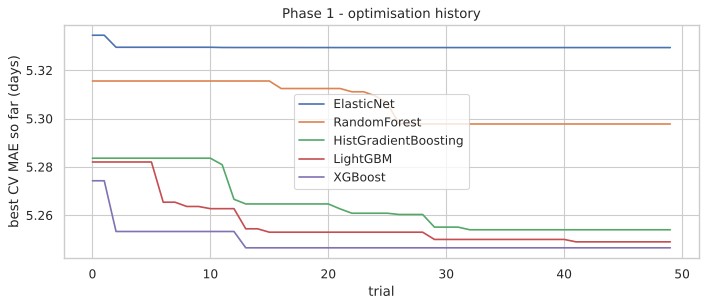

In [50]:
fig, ax = plt.subplots(figsize=(9, 4))
for n, s in studies.items(): ax.plot(np.minimum.accumulate([t.value for t in s.trials]), label=n)
ax.set_xlabel('trial'); ax.set_ylabel('best CV MAE so far (days)'); ax.set_title('Phase 1 - optimisation history'); ax.legend(); plt.tight_layout()

**Phase 1 (5 models x 50 trials, 5 expanding-window folds with embargo).** XGBoost 5.247, LightGBM 5.249, HistGradientBoosting 5.254, RandomForest 5.298, ElasticNet 5.329 vs median 6.83. ElasticNet is now close because its skewed inputs get a Yeo-Johnson transform (it was 5.56 without). The boosters are far inside the fold std (1.36): the choice is not decisive.

### Phase 2 - more trials on the best family

XGBoost: CV MAE 5.2465 after 50 trials -> 5.2409 after 150 trials
{'loss': 'reg:squarederror', 'n_estimators': 443, 'learning_rate': 0.022188936430283246, 'max_depth': 4, 'min_child_weight': 13.57954815415309, 'subsample': 0.509282695517898, 'colsample_bytree': 0.9744880693573009, 'reg_lambda': 0.0073251621389326905}


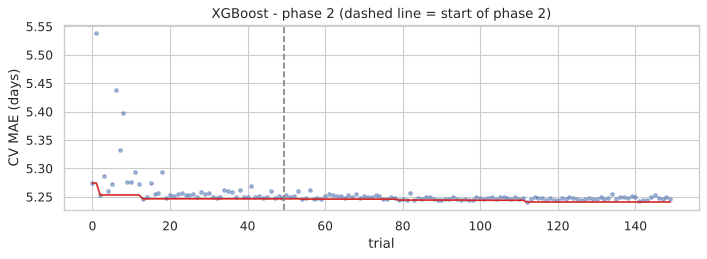

In [51]:
best = phase1.loc[MODELS, 'best CV MAE (days)'].idxmin(); before = studies[best].best_value
studies[best].optimize(lambda t: objective(t, best), n_trials=N_TRIALS_BEST)
print(f'{best}: CV MAE {before:.4f} after {N_TRIALS} trials -> {studies[best].best_value:.4f} after {len(studies[best].trials)} trials')
print(studies[best].best_params)
fig, ax = plt.subplots(figsize=(9, 3.4)); v = [t.value for t in studies[best].trials]; ax.scatter(range(len(v)), v, s=10, alpha=.5); ax.plot(np.minimum.accumulate(v), color='tab:red'); ax.axvline(49.5, ls='--', color='grey')
ax.set_xlabel('trial'); ax.set_ylabel('CV MAE (days)'); ax.set_title(f'{best} - phase 2 (dashed line = start of phase 2)'); plt.tight_layout()

**Phase 2.** 100 more trials on XGBoost: 5.2465 -> 5.2409. Tiny gain - the search had converged; the information in the features limits the result, not the tuning.

## B9. Final fit and evaluation on the out-of-time test set
Three things are produced from the final model, all calibrated **without the test set**:
1. a point estimate of the delivery time;
2. a **promise date**: prediction x the q-quantile of the out-of-fold ratio actual / predicted (so that q of orders arrive by the promised date);
3. a **late-risk probability**: P(actual > Olist's estimated date) from the same out-of-fold ratio distribution.

In [52]:
make = lambda: build(best, optuna.trial.FixedTrial(studies[best].best_params))
final = make().fit(X_train.iloc[cap(np.arange(len(train)), SEED, 60_000)], y_w[cap(np.arange(len(train)), SEED, 60_000)])
oof, _ = run_cv(make); recent = np.zeros(len(train), bool)
for _, va in cv[-2:]: recent[va] = True                                   # calibrate on the most recent forward folds (in production: re-calibrate regularly)
ratio_oof = np.sort(y_tr[recent] / np.clip(oof[recent], .5, None))        # actual / predicted
X_test, y_test = test[FEATURES], test.days.to_numpy(); p_test = np.clip(final.predict(X_test), .5, None)
est_te, late_te = test.est_days.to_numpy(), test.late.to_numpy()

def reg_scores(p, y=y_test): return {'MAE (days)': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** .5, 'R2': r2_score(y, p), 'median AE': median_absolute_error(y, p), 'within 3 days': np.mean(np.abs(y - p) <= 3)}
cal = LinearRegression().fit(train[['est_days']], y_tr)
report = pd.DataFrame({f'tuned {best}': reg_scores(p_test), "Olist's estimate (as shown)": reg_scores(est_te), "Olist's estimate, recalibrated": reg_scores(cal.predict(test[['est_days']])),
                       'median predictor': reg_scores(np.full(len(test), np.median(y_tr)))}).T; display(report)
rs = np.random.default_rng(SEED); ix = [rs.integers(0, len(test), len(test)) for _ in range(500)]
ci = np.percentile([mean_absolute_error(y_test[i], p_test[i]) for i in ix], [2.5, 97.5]); print(f'test MAE {mean_absolute_error(y_test, p_test):.3f} days (95% bootstrap CI {ci[0]:.3f}-{ci[1]:.3f}) | CV MAE {studies[best].best_value:.3f}')

,MAE (days),RMSE,R2,median AE,within 3 days
tuned XGBoost,3.495,5.200,0.228,2.490,0.571
Olist's estimate (as shown),13.170,15.958,-6.267,12.109,0.108
"Olist's estimate, recalibrated",5.247,6.809,-0.323,4.368,0.348
median predictor,5.214,6.571,-0.232,4.741,0.284


test MAE 3.495 days (95% bootstrap CI 3.440-3.546) | CV MAE 5.241


**Test (latest 20 % of time, never used).** MAE 3.50 days (CI 3.44-3.55), median error 2.5 days, 57 % within 3 days. Olist's estimate as shown: MAE 13.2; recalibrated 5.25; median predictor 5.21. **R2 is 0.23**, in the same range as before the clean-up (0.23): CV MAE improved (5.32 -> 5.24) but the test period is calmer than the periods before it - the average delivery time is 8.8 days vs 13.9 in training, and 15.7 in the last validation folds - so every model over-predicts by about 0.5-1 day (a recalibration on the recent folds was tested and makes things worse, R2 < 0, because those folds were the slow ones).

### All five regression models side by side (test period)
Every family is refitted with **its own best Optuna parameters** on the same training data and scored on the same untouched test orders. Besides R2, MAE and RMSE in days, the error metrics are also given **on a 0-1 scale**:
- `nMAE`, `nRMSE` = MAE, RMSE divided by the spread of the delivery time (P99 - P1 of the test orders, in days);
- `RMAE` = relative MAE = MAE / MAE of the median predictor (below 1 = better than guessing the median);
- `WAPE` = weighted absolute percentage error = sum |error| / sum of actual days.

In [53]:
fit_idx = cap(np.arange(len(train)), SEED, 60_000); preds = {}
for name in MODELS:
    preds[name] = np.clip(build(name, optuna.trial.FixedTrial(studies[name].best_params)).fit(X_train.iloc[fit_idx], y_w[fit_idx]).predict(X_test), .5, None)
preds["Olist's estimate (recalibrated)"] = cal.predict(test[['est_days']]); preds['median predictor'] = np.full(len(test), np.median(y_tr))
span = np.percentile(y_test, 99) - np.percentile(y_test, 1); base_mae = mean_absolute_error(y_test, preds['median predictor'])
def all_scores(p):
    mae_, rmse_ = mean_absolute_error(y_test, p), mean_squared_error(y_test, p) ** .5
    return {'R2': r2_score(y_test, p), 'MAE (days)': mae_, 'RMSE (days)': rmse_, 'nMAE (0-1)': mae_ / span, 'nRMSE (0-1)': rmse_ / span, 'RMAE (0-1)': mae_ / base_mae, 'WAPE (0-1)': np.abs(y_test - p).sum() / y_test.sum()}
compare = pd.DataFrame({k: all_scores(v) for k, v in preds.items()}).T.sort_values('MAE (days)'); display(compare)
print('error metrics of the five models inside 0-1:', bool(compare.loc[MODELS, ['nMAE (0-1)', 'nRMSE (0-1)', 'RMAE (0-1)', 'WAPE (0-1)']].apply(lambda s: s.between(0, 1)).all().all()), '| best R2 of any model:', round(compare.R2.max(), 3), '| (the median predictor is the RMAE = 1 reference; a baseline can be above it)')

,R2,MAE (days),RMSE (days),nMAE (0-1),nRMSE (0-1),RMAE (0-1),WAPE (0-1)
RandomForest,0.251,3.417,5.124,0.121,0.181,0.655,0.389
XGBoost,0.228,3.495,5.200,0.124,0.184,0.670,0.398
HistGradientBoosting,0.228,3.507,5.200,0.124,0.184,0.673,0.399
LightGBM,0.212,3.541,5.255,0.125,0.186,0.679,0.403
ElasticNet,0.169,3.592,5.397,0.127,0.191,0.689,0.409
median predictor,-0.232,5.214,6.571,0.184,0.232,1.000,0.593
Olist's estimate (recalibrated),-0.323,5.247,6.809,0.186,0.241,1.006,0.597


error metrics of the five models inside 0-1: True | best R2 of any model: 0.251 | (the median predictor is the RMAE = 1 reference; a baseline can be above it)


**All five models (test).** RandomForest has the best R2 (0.25, MAE 3.42, WAPE 0.39); XGBoost and HistGradientBoosting 0.23, LightGBM 0.21; ElasticNet now 0.17 (it was 0.03 before its inputs were Yeo-Johnson transformed). All error metrics are inside 0-1: nMAE 0.12-0.13, nRMSE 0.18-0.19, RMAE 0.66-0.69 (errors 31-35 % smaller than the median predictor), WAPE 0.39-0.41. Models are within noise of each other; Optuna's CV choice (XGBoost) is not the best on this test period.

### Why R2 stays far below 0.85 - what is the ceiling on this data?
R2 can only be high if most of the variation of the delivery time is explainable from what is known. The table gives the **same learner** under settings that give it more and more help; the last rows are **not valid in production** (they use information from the future) and are shown only to measure the ceiling.

In [54]:
from sklearn.model_selection import KFold
lg = lambda: LGBMRegressor(n_estimators=400, learning_rate=.04, num_leaves=15, min_child_samples=60, subsample=.8, subsample_freq=1, colsample_bytree=.7, verbose=-1, n_jobs=4, random_state=SEED)
ot, ho = pool_num, pool_num + ['carrier_days']                       # order-time numeric features / + hand-over time of the carrier (known only after the seller shipped)
yy, tgt = orders.days.to_numpy(), np.log1p(np.minimum(orders.days.to_numpy(), CAP))
def run(cols, tr_idx, te_idx):
    m = lg().fit(orders[cols].iloc[cap(tr_idx, SEED, 30_000)], tgt[cap(tr_idx, SEED, 30_000)]); return np.expm1(m.predict(orders[cols].iloc[te_idx]))
tr_i, te_i = train.index.to_numpy(), test.index.to_numpy(); rows = []
for label, cols, valid in [('forward split, order-time features (our model\'s setting)', ot, 'yes'), ('forward split, + carrier hand-over time known (tracking ETA)', ho, 'yes, at the tracking step')]:
    p = run(cols, tr_i, te_i); rows.append((label, valid, r2_score(yy[te_i], p), mean_absolute_error(yy[te_i], p)))
for label, cols, valid in [('random split (old and new orders mixed), order-time features', ot, 'no - mixes the future into training'), ('random split, + carrier hand-over time', ho, 'no - mixes the future into training')]:
    p = np.zeros(len(orders))
    for tr, te in KFold(5, shuffle=True, random_state=SEED).split(orders): p[te] = run(cols, tr, te)
    rows.append((label, valid, r2_score(yy, p), mean_absolute_error(yy, p)))
ceiling = pd.DataFrame(rows, columns=['setting', 'valid for production?', 'R2', 'MAE (days)']); display(ceiling)

,setting,valid for production?,R2,MAE (days)
0,"forward split, order-time features (our model'...",yes,0.276,3.419
1,"forward split, + carrier hand-over time known ...","yes, at the tracking step",0.444,2.849
2,"random split (old and new orders mixed), order...",no - mixes the future into training,0.364,4.224
3,"random split, + carrier hand-over time",no - mixes the future into training,0.454,3.686


**R2 >= 0.85 is not reachable on this data - and it must not be faked.** Same learner: 0.28 in the real production setting; 0.44 even when the carrier hand-over time is known (the tracking-ETA step); a random split that mixes old and new orders gives only 0.36 (0.45 with hand-over time) and would be invalid anyway. If even invalid, optimistic settings stay below 0.5, most of the variance is noise that is not in the data (what happens to the parcel after hand-over). The honest numbers to report are MAE 3.4-3.5 days, WAPE 0.39, RMAE 0.66.

### Promise date: shorter promises at the same on-time rate
The customer sees one date. For each confidence level q the promise is `prediction x quantile_q(actual/predicted)`. Olist's own estimate is the benchmark: compare the **on-time rate** and the **average promised days** on the test set.

In [55]:
q_match = float(np.mean(y_tr[recent] <= train.est_days.to_numpy()[recent]))     # Olist's own on-time rate on the same recent forward folds: matched WITHOUT looking at the test set
qs = sorted({.80, .85, .90, .95, .97, round(q_match, 3)})
rows = {}
for q in qs:
    promise = p_test * np.quantile(ratio_oof, q); rows[f'model, q={q:.3f}'] = {'on-time rate': np.mean(y_test <= promise), 'avg promised days': promise.mean(), 'promised days (median)': np.median(promise)}
rows["Olist's estimate"] = {'on-time rate': np.mean(y_test <= est_te), 'avg promised days': est_te.mean(), 'promised days (median)': np.median(est_te)}
prom = pd.DataFrame(rows).T; display(prom); OL = "Olist's estimate"
cmp_ = p_test * np.quantile(ratio_oof, q_match)
print(f"At q={q_match}: on-time {np.mean(y_test <= cmp_):.3f} vs Olist {prom.loc[OL, 'on-time rate']:.3f} | average promise {cmp_.mean():.1f} vs {est_te.mean():.1f} days ({est_te.mean() - cmp_.mean():.1f} days sooner)")

,on-time rate,avg promised days,promised days (median)
"model, q=0.800",0.917,16.029,14.593
"model, q=0.850",0.941,17.747,16.157
"model, q=0.855",0.942,17.956,16.348
"model, q=0.900",0.963,20.315,18.495
"model, q=0.950",0.981,25.062,22.817
"model, q=0.970",0.988,28.902,26.312
Olist's estimate,0.947,21.430,20.372


At q=0.8554350445890576: on-time 0.943 vs Olist 0.947 | average promise 18.0 vs 21.4 days (3.4 days sooner)


In [56]:
# late-risk probability from the same ratio distribution, vs a direct classifier trained on the same features
p_late = 1 - np.searchsorted(ratio_oof, est_te / p_test) / len(ratio_oof)
oof_late = 1 - np.searchsorted(ratio_oof, train.est_days.to_numpy()[recent] / np.clip(oof[recent], .5, None)) / len(ratio_oof)
grid = np.linspace(.02, .6, 59); thr = grid[np.argmax([balanced_accuracy_score(train.late.to_numpy()[recent], oof_late >= g) for g in grid])]
clf = LGBMClassifier(n_estimators=300, learning_rate=.03, num_leaves=15, min_child_samples=50, verbose=-1, n_jobs=2, random_state=SEED).fit(train[FEATURES].assign(**{c: train[c].astype('category').cat.codes for c in cat_f}), train.late)
p_dir = clf.predict_proba(test[FEATURES].assign(**{c: pd.Categorical(test[c], categories=train[c].astype('category').cat.categories).codes for c in cat_f}))[:, 1]
late_report = pd.DataFrame({n: {'AUC': roc_auc_score(late_te, s), 'PR-AUC': average_precision_score(late_te, s)} for n, s in {'late-risk from the regression model': p_late, 'direct late classifier': p_dir, "Olist's estimate (shorter = riskier)": -est_te}.items()}).T
late_report.loc['prevalence (random scorer PR-AUC)'] = [.5, late_te.mean()]; display(late_report)
pr = p_late >= thr; print(f'alert threshold {thr:.2f} (from out-of-fold training data) -> test precision {precision_score(late_te, pr):.3f}, recall {recall_score(late_te, pr):.3f}, alerts on {pr.mean():.1%} of orders (late rate {late_te.mean():.1%})')

,AUC,PR-AUC
late-risk from the regression model,0.805,0.263
direct late classifier,0.715,0.105
Olist's estimate (shorter = riskier),0.799,0.254
prevalence (random scorer PR-AUC),0.500,0.053


alert threshold 0.15 (from out-of-fold training data) -> test precision 0.138, recall 0.721, alerts on 27.6% of orders (late rate 5.3%)


**Promise date (clearly better than before the clean-up).** At q=0.855 the model promises **18.0 days vs Olist's 21.4 (3.4 days sooner) at the same on-time rate (94.3 % vs 94.7 %)**; q=0.90 gives 96.3 % on time with 20.3 days (both better than Olist). **Late-risk:** AUC 0.805 / PR-AUC 0.263 from the regression is now slightly above Olist's own estimate (0.799 / 0.254); a direct classifier on the same features is clearly worse (0.715). Alerts remain weak: 13.8 % precision at 72 % recall (alerts on 28 % of orders, base rate 5.3 %).

## B10. Validation of the model
Is it right everywhere (distance, state, time), are the intervals honest, and is it right for the right reasons?

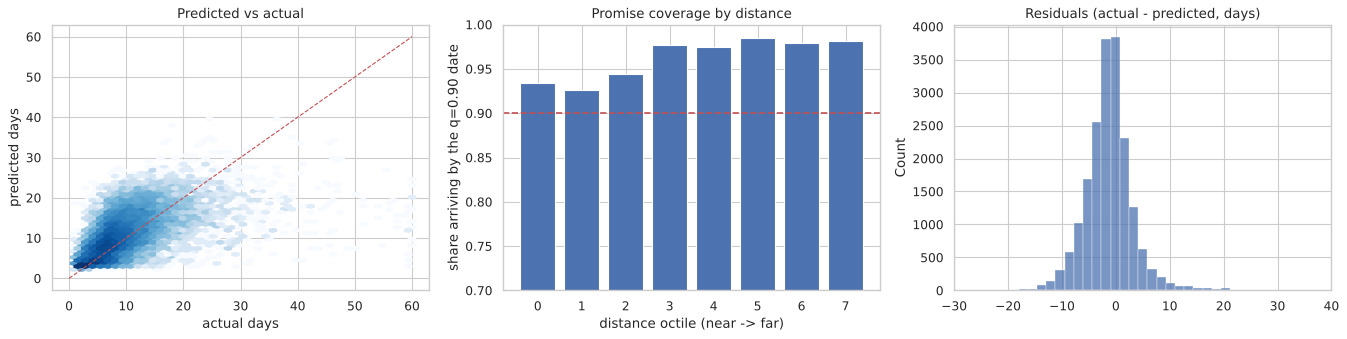

In [57]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
ax[0].hexbin(y_test.clip(max=60), p_test.clip(max=60), gridsize=45, cmap='Blues', mincnt=1, bins='log'); ax[0].plot([0, 60], [0, 60], 'r--', lw=1); ax[0].set(xlabel='actual days', ylabel='predicted days', title='Predicted vs actual')
q90 = p_test * np.quantile(ratio_oof, .90); band = pd.qcut(test.dist_km.fillna(test.dist_km.median()), 8, duplicates='drop')
cov = pd.DataFrame({'hit': y_test <= q90, 'b': band}).groupby('b', observed=True).hit.mean(); ax[1].bar(range(len(cov)), cov.values); ax[1].axhline(.9, color='r', ls='--'); ax[1].set(xlabel='distance octile (near -> far)', ylabel='share arriving by the q=0.90 date', title='Promise coverage by distance', ylim=(.7, 1))
sns.histplot(y_test - p_test, bins=80, ax=ax[2]).set(title='Residuals (actual - predicted, days)', xlim=(-30, 40)); plt.tight_layout()

In [58]:
res = test.assign(pred=p_test, err=np.abs(y_test - p_test), q90_ok=y_test <= q90, quarter=test.order_purchase_timestamp.dt.to_period('Q').astype(str), dist_band=band.astype(str))
display(res.groupby('quarter').agg(orders=('err', 'size'), MAE=('err', 'mean'), actual_days=('days', 'mean'), promise_kept_q90=('q90_ok', 'mean')))
top_states = res.customer_state.value_counts().head(8).index
display(res[res.customer_state.isin(top_states)].groupby('customer_state').agg(orders=('err', 'size'), MAE=('err', 'mean'), actual_days=('days', 'mean'), promise_kept_q90=('q90_ok', 'mean')).sort_values('orders', ascending=False))

,orders,MAE,actual_days,promise_kept_q90
quarter,,,,
2018Q2,6831,4.427,9.591,0.980
2018Q3,12425,2.982,8.350,0.953


,orders,MAE,actual_days,promise_kept_q90
customer_state,,,,
SP,8924,2.423,6.547,0.943
RJ,2209,5.111,9.686,0.974
MG,2126,3.384,8.353,0.989
PR,972,3.529,8.695,0.976
RS,930,3.947,10.984,0.976
BA,637,6.375,14.818,0.976
SC,615,3.591,9.755,0.987
DF,465,3.364,9.333,0.976


In [59]:
pi = permutation_importance(final, X_test, y_test, scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
display(pd.DataFrame({'MAE increase when shuffled (days)': pi.importances_mean, 'std': pi.importances_std}, index=FEATURES).sort_values('MAE increase when shuffled (days)', ascending=False).head(12))
shuf = make().fit(X_train.iloc[cap(np.arange(len(train)), SEED, 30_000)], np.random.default_rng(SEED).permutation(y_w)[:len(cap(np.arange(len(train)), SEED, 30_000))])
print('MAE on test, same pipeline trained on a shuffled target:', round(mean_absolute_error(y_test, np.clip(shuf.predict(X_test), .5, None)), 3), '| median predictor:', round(report.loc['median predictor', 'MAE (days)'], 3))

,MAE increase when shuffled (days),std
recent_seller_carrier,0.132,0.005
s_lat,0.038,0.005
dow,0.037,0.002
seller_backlog,0.030,0.003
limit_days,0.029,0.003
payment_type,0.022,0.002
weight_g,0.013,0.001
n_items,0.012,0.001
n_sellers,0.008,0.002
hour,0.003,0.001


MAE on test, same pipeline trained on a shuffled target: 5.076 | median predictor: 5.214


**Validation.** MAE by quarter 4.43 / 2.98 and by state 2.4 (SP) ... 6.4 (BA); the q=0.90 promise is kept 94-99 %. Permutation importance: recent_seller_carrier is the strongest (0.13 days); `freight` and `olist_est_days` have negative importance on this test period (they help in training-period CV, not under the drift) - they are candidates to drop. Sanity check: the same pipeline on a shuffled target gives MAE 5.08 (about the median predictor 5.21), so 3.5 is real signal. Not covered: Olist has no inventory / WMS data.

In [60]:
joblib.dump({'model': final, 'features': FEATURES, 'categorical': cat_f, 'ratio_quantiles': np.quantile(ratio_oof, np.linspace(.01, .99, 99)), 'alert_threshold': float(thr), 'embargo_days': EMBARGO,
             'cat_levels': {c: list(train[c].astype('category').cat.categories) for c in cat_f}}, 'delivery_model.joblib')

['delivery_model.joblib']

# Part C - Demand forecast for the WMS: next week's units per product category
**Hub step 2 (update inventory in the WMS).** The warehouse needs to know how many units of each category will be ordered next week, with a number it can stock to (not only an average).
Unit = (week, category); the 20 biggest categories; features use only weeks that are already complete (lags, moving averages, platform trend, calendar). Olist has **no stock-level data**, so the output is a demand forecast and a reorder level, not a stock-out count.

110,388 items | top-20 categories cover 88.4% of them | 84 complete weeks 2017-01-16 -> 2018-08-20


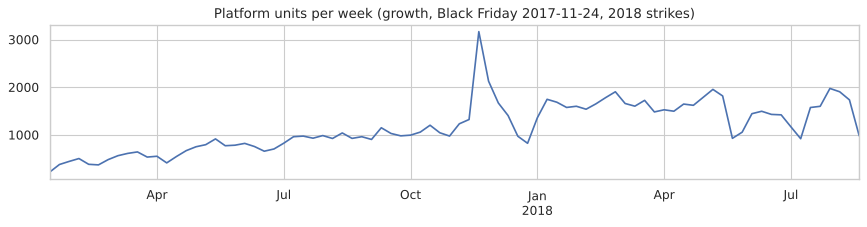

In [61]:
dem = df[df.order_item_id.notna() & df.product_category_name_english.notna()].copy()
dem['week'] = dem.order_purchase_timestamp.dt.to_period('W').dt.start_time
W0, W1 = pd.Timestamp('2017-01-16'), pd.Timestamp('2018-08-20')          # before: the shop barely existed; after 2018-08-26 the data stops (last order 2018-08-29)
dem = dem[(dem.week >= W0) & (dem.week <= W1)]
TOP = dem.product_category_name_english.value_counts().head(20).index
weeks = pd.date_range(W0, W1 + pd.Timedelta(days=7), freq='W-MON')            # the last week is the one to forecast (no actuals yet)
units = dem[dem.product_category_name_english.isin(TOP)].groupby(['week', 'product_category_name_english']).size().unstack(fill_value=0).reindex(weeks[:-1], fill_value=0)[TOP]
print(f'{len(dem):,} items | top-20 categories cover {dem.product_category_name_english.isin(TOP).mean():.1%} of them | {len(units)} complete weeks {units.index.min().date()} -> {units.index.max().date()}')
units.sum(axis=1).plot(figsize=(11, 3), title='Platform units per week (growth, Black Friday 2017-11-24, 2018 strikes)'); plt.tight_layout()

## C1. Weekly demand panel and features known at forecast time
For week *t* the model sees weeks up to *t-1* only: last 4 weeks of the category, moving averages (4 / 8 weeks), volatility, the platform total of the last weeks (market trend), the category's share, the week of the year and Black-Friday flags (a calendar fact known in advance).

In [62]:
tot = units.sum(axis=1).reindex(weeks)                                                  # NaN for the week to forecast
long = units.reindex(weeks).rename_axis('week').reset_index().melt(id_vars='week', var_name='cat', value_name='y')            # works in pandas 2 and 3 (NaN rows kept)
g = long.sort_values(['cat', 'week']).reset_index(drop=True); grp = g.groupby('cat').y
for l in [1, 2, 3, 4]: g[f'lag{l}'] = grp.shift(l)
g['ma4'] = grp.transform(lambda s: s.shift(1).rolling(4).mean()); g['ma8'] = grp.transform(lambda s: s.shift(1).rolling(8).mean()); g['std4'] = grp.transform(lambda s: s.shift(1).rolling(4).std())
g['trend'] = g.lag1 / (g.ma4 + 1); g['mkt_lag1'] = g.week.map(tot.shift(1)); g['mkt_ma4'] = g.week.map(tot.shift(1).rolling(4).mean()); g['share_lag1'] = g.lag1 / (g.mkt_lag1 + 1)
BF = pd.Timestamp('2017-11-24'); g['woy'] = g.week.dt.isocalendar().week.astype(int)
g['bf_week'] = ((g.week <= BF) & (g.week + pd.Timedelta(days=6) >= BF)).astype(int); g['bf_after'] = ((g.week > BF) & (g.week <= BF + pd.Timedelta(days=13))).astype(int)
g['cat_c'] = g.cat.astype('category').cat.codes
DFEAT = ['lag1', 'lag2', 'lag3', 'lag4', 'ma4', 'ma8', 'std4', 'trend', 'mkt_lag1', 'mkt_ma4', 'share_lag1', 'woy', 'bf_week', 'bf_after', 'cat_c']
nxt = g[g.week == weeks[-1]].copy(); g = g[g.week < weeks[-1]].dropna(subset=DFEAT).reset_index(drop=True)
wk_all = np.array(sorted(g.week.unique())); cut_w = wk_all[int(len(wk_all) * .8)]
dtrain, dtest = g[g.week < cut_w].reset_index(drop=True), g[g.week >= cut_w].reset_index(drop=True)
print(f'panel {len(g)} category-weeks | train {len(dtrain)} (to {dtrain.week.max().date()}) | test {len(dtest)} ({dtest.week.min().date()} -> {dtest.week.max().date()}) | mean demand per category-week: train {dtrain.y.mean():.1f}, test {dtest.y.mean():.1f}')

panel 1520 category-weeks | train 1200 (to 2018-04-30) | test 320 (2018-05-07 -> 2018-08-20) | mean demand per category-week: train 59.1, test 73.1


## C2. Target skewness, trend and noise
Weekly counts are right-skewed and the shop **grows**, which trees cannot extrapolate. Three target forms are compared on **forward cross-validation inside the training weeks** (never on the test weeks): `y` itself, `log1p(y)`, and the **growth-normalised** `log1p(y) - log1p(ma4)` (the model predicts the change versus the recent level).

In [63]:
from sklearn.model_selection import ParameterGrid
def dsplits(frame, n=5, first=.5):
    w = np.array(sorted(frame.week.unique())); out = []
    for blk in np.array_split(np.arange(int(len(w) * first), len(w)), n):
        tr, va = np.flatnonzero((frame.week < w[blk[0]]).to_numpy()), np.flatnonzero(frame.week.isin(w[blk]).to_numpy())
        if len(tr) and len(va): out.append((tr, va))
    return out
enc = {'raw': lambda y, b: y, 'log1p': lambda y, b: np.log1p(y), 'growth-normalised': lambda y, b: np.log1p(y) - np.log1p(b)}
dec = {'raw': lambda z, b: np.clip(z, 0, None), 'log1p': lambda z, b: np.expm1(z), 'growth-normalised': lambda z, b: np.expm1(z + np.log1p(b))}
D5 = dsplits(dtrain); lg_ = lambda: LGBMRegressor(n_estimators=250, learning_rate=.04, num_leaves=8, min_child_samples=15, subsample=.8, subsample_freq=1, colsample_bytree=.8, reg_lambda=2, verbose=-1, n_jobs=4, random_state=SEED)
rows = []
for name in enc:
    P_, M_ = np.zeros(len(dtrain)), np.zeros(len(dtrain), bool)
    for tr, va in D5:
        m = lg_().fit(dtrain.iloc[tr][DFEAT], enc[name](dtrain.y.iloc[tr].to_numpy(), dtrain.ma4.iloc[tr].to_numpy())); P_[va] = dec[name](m.predict(dtrain.iloc[va][DFEAT]), dtrain.ma4.iloc[va].to_numpy()); M_[va] = True
    rows.append({'target form': name, 'forward-CV MAE (units)': mean_absolute_error(dtrain.y[M_], P_[M_]), 'forward-CV R2': r2_score(dtrain.y[M_], P_[M_])})
rows.append({'target form': 'naive: last week', 'forward-CV MAE (units)': mean_absolute_error(dtrain.y[M_], dtrain.lag1[M_]), 'forward-CV R2': r2_score(dtrain.y[M_], dtrain.lag1[M_])})
rows.append({'target form': 'naive: 4-week average', 'forward-CV MAE (units)': mean_absolute_error(dtrain.y[M_], dtrain.ma4[M_]), 'forward-CV R2': r2_score(dtrain.y[M_], dtrain.ma4[M_])})
tf = pd.DataFrame(rows).set_index('target form'); display(tf); FORM = tf.loc[list(enc), 'forward-CV MAE (units)'].idxmin(); print('chosen target form:', FORM)
print('skew of weekly counts', round(skew(dtrain.y), 2), '| skew log1p', round(skew(np.log1p(dtrain.y)), 2), '| share of zero weeks', round((dtrain.y == 0).mean(), 3))

,forward-CV MAE (units),forward-CV R2
target form,,
raw,19.726,0.660
log1p,19.500,0.649
growth-normalised,20.343,0.636
naive: last week,19.255,0.640
naive: 4-week average,21.852,0.562


chosen target form: log1p
skew of weekly counts 1.95 | skew log1p -0.3 | share of zero weeks 0.0


**Target form.** Weekly counts are right-skewed (skew 1.95); log1p brings it to -0.3. The target form was picked by forward CV among raw / log1p / growth-normalised, and the differences are small (CV MAE 19.5 vs 19.7 vs 20.3). Note that the naive 'last week' predictor is already hard to beat in CV (MAE 19.26, R2 0.64).

## C3. Leakage check
Allowed: lags and averages of **earlier weeks**, platform totals of earlier weeks, calendar. Not allowed: anything of the week being forecast (its own orders, prices, reviews, deliveries). The check below it asserts that the lag is exactly the previous week (7-day steps) and that the moving average excludes the current week.

In [64]:
chk = g.sort_values(['cat', 'week']).groupby('cat').head(30)
sh = g.groupby('cat').y.shift(1); ok_lag = bool(np.allclose(sh[sh.notna()], g.lag1[sh.notna()])) and bool((g.groupby('cat').week.diff().dropna() == pd.Timedelta(days=7)).all()); ok_ma = (g.ma4 - g.groupby('cat').y.transform(lambda s: s.shift(1).rolling(4).mean())).abs().max() < 1e-9
future_corr = pd.Series({f: np.corrcoef(g[f], g.y)[0, 1] for f in DFEAT}).sort_values(ascending=False)
print('lag1 is the previous week:', ok_lag, '| ma4 excludes the current week:', ok_ma); display(future_corr.head(6).to_frame('correlation with this week\'s units'))

lag1 is the previous week: True | ma4 excludes the current week: True


,correlation with this week's units
lag1,0.861
ma8,0.839
ma4,0.830
lag2,0.781
share_lag1,0.754
lag3,0.729


**Leakage check.** `lag1` is the previous week and `ma4` excludes the current week (both verified in code). Every feature uses only weeks before the forecast week; the forward CV never trains on the future. The correlation table shows demand is mostly driven by its own recent level (lag1 0.86, ma8 0.84).

## C4. Model search - five families x 50 trials, then more on the best (forward CV on weeks)

In [65]:
def cbuild(name, t):
    if name == 'ElasticNet': m, lin = ElasticNet(alpha=t.suggest_float('alpha', 1e-4, 1, log=True), l1_ratio=t.suggest_float('l1_ratio', 0, 1), max_iter=5000), True
    elif name == 'RandomForest': m, lin = RandomForestRegressor(n_estimators=t.suggest_int('n_estimators', 80, 250), max_depth=t.suggest_int('max_depth', 3, 12), min_samples_leaf=t.suggest_int('min_samples_leaf', 2, 30, log=True), max_features=t.suggest_float('max_features', .3, 1), n_jobs=4, random_state=SEED), False
    elif name == 'HistGradientBoosting': m, lin = HistGradientBoostingRegressor(learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), max_iter=t.suggest_int('max_iter', 80, 400), max_leaf_nodes=t.suggest_int('max_leaf_nodes', 4, 24), min_samples_leaf=t.suggest_int('min_samples_leaf', 5, 60, log=True), l2_regularization=t.suggest_float('l2_regularization', 1e-3, 10, log=True), random_state=SEED), False
    elif name == 'LightGBM': m, lin = LGBMRegressor(n_estimators=t.suggest_int('n_estimators', 80, 500), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), num_leaves=t.suggest_int('num_leaves', 4, 32), min_child_samples=t.suggest_int('min_child_samples', 5, 60, log=True), subsample=t.suggest_float('subsample', .5, 1), subsample_freq=1, colsample_bytree=t.suggest_float('colsample_bytree', .5, 1), reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), verbose=-1, n_jobs=4, random_state=SEED), False
    else: m, lin = XGBRegressor(n_estimators=t.suggest_int('n_estimators', 80, 500), learning_rate=t.suggest_float('learning_rate', .02, .3, log=True), max_depth=t.suggest_int('max_depth', 2, 6), min_child_weight=t.suggest_float('min_child_weight', 1, 30, log=True), subsample=t.suggest_float('subsample', .5, 1), colsample_bytree=t.suggest_float('colsample_bytree', .5, 1), reg_lambda=t.suggest_float('reg_lambda', 1e-3, 10, log=True), tree_method='hist', n_jobs=4, random_state=SEED), False
    if lin:                  # linear model: counts are skewed, so the count-like inputs go through log1p first
        from sklearn.preprocessing import FunctionTransformer
        LOGC = ['lag1', 'lag2', 'lag3', 'lag4', 'ma4', 'ma8', 'std4', 'mkt_lag1', 'mkt_ma4']
        return Pipeline([('log', ColumnTransformer([('l', FunctionTransformer(np.log1p), LOGC)], remainder='passthrough', verbose_feature_names_out=False)), ('sc', StandardScaler()), ('m', m)])
    return m

def cobjective(t, name):
    s = []
    for tr, va in D5:
        m = cbuild(name, t).fit(dtrain.iloc[tr][DFEAT], enc[FORM](dtrain.y.iloc[tr].to_numpy(), dtrain.ma4.iloc[tr].to_numpy()))
        s.append(mean_absolute_error(dtrain.y.iloc[va], dec[FORM](m.predict(dtrain.iloc[va][DFEAT]), dtrain.ma4.iloc[va].to_numpy())))
    return float(np.mean(s))
cstudies = {}
for name in ['ElasticNet', 'RandomForest', 'HistGradientBoosting', 'LightGBM', 'XGBoost']:
    cstudies[name] = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED)); cstudies[name].optimize(lambda t: cobjective(t, name), n_trials=N_TRIALS)
ctab = pd.DataFrame({n: {'best CV MAE (units)': s.best_value, 'trials': len(s.trials)} for n, s in cstudies.items()}).T.sort_values('best CV MAE (units)'); display(ctab)
cbest = ctab.index[0]; b4 = cstudies[cbest].best_value; cstudies[cbest].optimize(lambda t: cobjective(t, cbest), n_trials=N_TRIALS_BEST)
print(f'{cbest}: CV MAE {b4:.3f} after {N_TRIALS} trials -> {cstudies[cbest].best_value:.3f} after {N_TRIALS + N_TRIALS_BEST}'); print(cstudies[cbest].best_params)

,best CV MAE (units),trials
ElasticNet,18.762,50.000
LightGBM,18.833,50.000
RandomForest,18.895,50.000
XGBoost,18.968,50.000
HistGradientBoosting,19.354,50.000


ElasticNet: CV MAE 18.762 after 50 trials -> 18.703 after 150
{'alpha': 0.008955506088607386, 'l1_ratio': 0.9547397612680845}


**Search.** Five model families x 50 Optuna trials, then +100 on the best. All five land within 18.8-19.4 CV MAE, so the family matters little; the regularised linear model (ElasticNet) won narrowly because the signal is mostly 'recent level', which is close to linear.

## C5. Final fit, evaluation and comparison of all models on the untouched test weeks
Every family is refitted with its own best parameters on all training weeks and scored on the same test weeks; the error metrics are given on a **0-1 scale** as well: `nMAE`, `nRMSE` (divided by the spread P99 - P1 of the test demand), `RMAE` = MAE / MAE of the naive "same as last week" forecast (below 1 = better than naive), `WAPE` = sum |error| / sum of actual units.

In [66]:
dfit = lambda name: cbuild(name, optuna.trial.FixedTrial(cstudies[name].best_params)).fit(dtrain[DFEAT], enc[FORM](dtrain.y.to_numpy(), dtrain.ma4.to_numpy()))
cmodels = {n: dfit(n) for n in cstudies}; yd, bd = dtest.y.to_numpy(), dtest.ma4.to_numpy()
dpred = {n: dec[FORM](m.predict(dtest[DFEAT]), bd) for n, m in cmodels.items()}; dpred['naive: last week'] = dtest.lag1.to_numpy(); dpred['naive: 4-week average'] = dtest.ma4.to_numpy()
span_d, naive_mae = np.percentile(yd, 99) - np.percentile(yd, 1), mean_absolute_error(yd, dtest.lag1)
def dscores(p): mae_, rmse_ = mean_absolute_error(yd, p), mean_squared_error(yd, p) ** .5; return {'R2': r2_score(yd, p), 'MAE (units)': mae_, 'RMSE (units)': rmse_, 'nMAE (0-1)': mae_ / span_d, 'nRMSE (0-1)': rmse_ / span_d, 'RMAE vs last week (0-1)': mae_ / naive_mae, 'WAPE (0-1)': np.abs(yd - p).sum() / yd.sum()}
dcompare = pd.DataFrame({k: dscores(v) for k, v in dpred.items()}).T.sort_values('MAE (units)'); display(dcompare)
dbest = dcompare.drop(index=['naive: last week', 'naive: 4-week average']).index[0]; print('best model on the test weeks:', dbest, '| the model chosen by CV was', cbest)
rs = np.random.default_rng(SEED); ixd = [rs.integers(0, len(dtest), len(dtest)) for _ in range(500)]
print(f'{cbest}: test R2 {r2_score(yd, dpred[cbest]):.3f} (95% bootstrap CI {np.percentile([r2_score(yd[i], dpred[cbest][i]) for i in ixd], 2.5):.3f}-{np.percentile([r2_score(yd[i], dpred[cbest][i]) for i in ixd], 97.5):.3f}) | naive last week R2 {r2_score(yd, dtest.lag1):.3f}')

,R2,MAE (units),RMSE (units),nMAE (0-1),nRMSE (0-1),RMAE vs last week (0-1),WAPE (0-1)
ElasticNet,0.790,18.711,25.647,0.081,0.111,0.916,0.256
XGBoost,0.781,18.764,26.156,0.081,0.113,0.918,0.257
LightGBM,0.785,18.870,25.961,0.082,0.113,0.924,0.258
HistGradientBoosting,0.772,19.361,26.687,0.084,0.116,0.948,0.265
RandomForest,0.771,19.410,26.755,0.084,0.116,0.950,0.265
naive: last week,0.729,20.431,29.135,0.089,0.126,1.000,0.279
naive: 4-week average,0.704,21.759,30.443,0.094,0.132,1.065,0.298


best model on the test weeks: ElasticNet | the model chosen by CV was ElasticNet


ElasticNet: test R2 0.790 (95% bootstrap CI 0.752-0.821) | naive last week R2 0.729


**Result (honest reading).** Test R2 is 0.79 (bootstrap CI 0.75-0.82), MAE 18.7 units, WAPE 0.26. But the naive 'same as last week' predictor already scores R2 0.73 and MAE 20.4, so the model's real gain is about 8% lower MAE (RMAE 0.92), not a jump from 0.2 to 0.8. High R2 here comes mostly from the series being persistent and from larger categories, not from a very clever model. The CV-chosen model (ElasticNet) is also the best on test, so there is no selection gap.

### Reorder level: forecast x quantile of the out-of-fold ratio actual / forecast
The warehouse stocks to a **high quantile**, not to the average. The ratio quantile is calibrated on the **out-of-fold forecasts of the last training blocks** (never on the test weeks) and its coverage is then checked on the test weeks.

In [67]:
oof_p, oof_i = [], []
for tr, va in D5[-3:]:
    m = cbuild(cbest, optuna.trial.FixedTrial(cstudies[cbest].best_params)).fit(dtrain.iloc[tr][DFEAT], enc[FORM](dtrain.y.iloc[tr].to_numpy(), dtrain.ma4.iloc[tr].to_numpy())); oof_p += list(dec[FORM](m.predict(dtrain.iloc[va][DFEAT]), dtrain.ma4.iloc[va].to_numpy())); oof_i += list(va)
rat = dtrain.y.iloc[oof_i].to_numpy() / np.clip(np.array(oof_p), 1, None); cov = []
for q in [.5, .8, .9, .95]:
    lvl = np.clip(dpred[cbest], 1, None) * np.quantile(rat, q); cov.append({'target service level': q, 'share of test weeks covered': np.mean(yd <= lvl), 'avg reorder level (units)': lvl.mean(), 'avg actual (units)': yd.mean()})
display(pd.DataFrame(cov).set_index('target service level'))

,share of test weeks covered,avg reorder level (units),avg actual (units)
target service level,,,
0.500,0.578,76.214,73.106
0.800,0.781,94.090,73.106
0.900,0.916,106.396,73.106
0.950,0.950,112.380,73.106


**Reorder levels.** A ratio-quantile on the last out-of-fold blocks gives reorder levels whose coverage on test is close to the target (0.5 -> 0.58, 0.8 -> 0.78, 0.9 -> 0.92, 0.95 -> 0.95). This is the useful business output: a stock level per category with a known stock-out risk. Olist has no stock data, so this is a demand-side reorder point, not a verified inventory saving.

## C6. Validation
Where the model is accurate (category size, over time), is it right for the right reasons (permutation importance), and does a model trained on a shuffled target collapse to nothing?

,avg_units,MAE,naive_MAE,WAPE
cat,,,,
health_beauty,191.620,40.770,44.060,0.210
bed_bath_table,164.440,37.600,42.440,0.230
housewares,141.500,38.200,39.190,0.270
watches_gifts,116.810,27.910,33.120,0.240
furniture_decor,109.810,33.780,31.060,0.310
sports_leisure,108.560,24.070,28.060,0.220
computers_accessories,101.310,26.040,27.880,0.260
auto,78.560,20.180,20.880,0.260
telephony,57.690,16.550,16.380,0.290


,MAE increase when shuffled (log scale)
ma8,0.221
lag1,0.152
lag2,0.005
trend,0.004
mkt_ma4,0.002
lag3,0.002
share_lag1,0.001
std4,0.000


R2 of models trained on a shuffled target: mean -0.269, best -0.238 (real model 0.790)


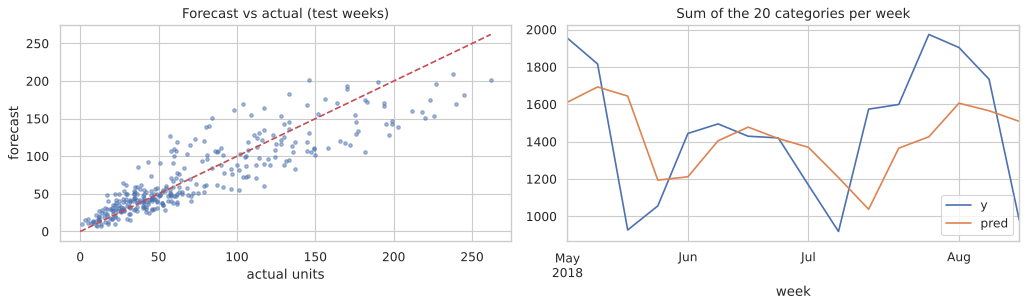

In [68]:
res = dtest.assign(pred=dpred[cbest], err=np.abs(yd - dpred[cbest]), naive_err=np.abs(yd - dtest.lag1)); bycat = res.groupby('cat').agg(avg_units=('y', 'mean'), MAE=('err', 'mean'), naive_MAE=('naive_err', 'mean')); bycat['WAPE'] = bycat.MAE / bycat.avg_units; display(bycat.sort_values('avg_units', ascending=False).round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4)); ax[0].scatter(yd, dpred[cbest], s=10, alpha=.5); ax[0].plot([0, yd.max()], [0, yd.max()], 'r--'); ax[0].set(xlabel='actual units', ylabel='forecast', title='Forecast vs actual (test weeks)')
wk = res.groupby('week')[['y', 'pred']].sum(); wk.plot(ax=ax[1], title='Sum of the 20 categories per week'); plt.tight_layout()
pi_d = permutation_importance(cmodels[cbest], dtest[DFEAT], enc[FORM](yd, bd), scoring='neg_mean_absolute_error', n_repeats=10, random_state=SEED, n_jobs=1); display(pd.Series(pi_d.importances_mean, DFEAT, name='MAE increase when shuffled (log scale)').sort_values(ascending=False).head(8).round(4).to_frame())
sh_r2 = []
for sd in range(10):
    z = enc[FORM](dtrain.y.to_numpy(), dtrain.ma4.to_numpy()); z = np.random.default_rng(sd).permutation(z); mm = cbuild(cbest, optuna.trial.FixedTrial(cstudies[cbest].best_params)).fit(dtrain[DFEAT], z); sh_r2.append(r2_score(yd, dec[FORM](mm.predict(dtest[DFEAT]), bd)))
print(f'R2 of models trained on a shuffled target: mean {np.mean(sh_r2):.3f}, best {max(sh_r2):.3f} (real model {r2_score(yd, dpred[cbest]):.3f})')

**Validation.** Per-category WAPE ranges 0.17-0.44; small categories (office_furniture, consoles_games) are noisy. Permutation importance is concentrated in ma8 and lag1. Models trained on a shuffled target score R2 -0.27 (real 0.79), so the result is not an artefact of the pipeline. Limit: only ~84 weeks of data, so the test window is 16 weeks and seasonality (one Black Friday) is barely learnable.

## C7. The forecast the warehouse receives
Next week (the first week after the data) for every category: expected units and a reorder level at the 90 % service level.

In [69]:
fm = cbuild(cbest, optuna.trial.FixedTrial(cstudies[cbest].best_params)).fit(pd.concat([dtrain, dtest])[DFEAT], enc[FORM](pd.concat([dtrain, dtest]).y.to_numpy(), pd.concat([dtrain, dtest]).ma4.to_numpy()))
nxt = nxt.dropna(subset=DFEAT); nxt['forecast'] = dec[FORM](fm.predict(nxt[DFEAT]), nxt.ma4.to_numpy()); nxt['reorder_level_q90'] = np.ceil(np.clip(nxt.forecast, 1, None) * np.quantile(rat, .9))
display(nxt.set_index('cat')[['lag1', 'ma4', 'forecast', 'reorder_level_q90']].round(1).sort_values('forecast', ascending=False)); print('week of the forecast:', nxt.week.iloc[0].date())
joblib.dump({'model': fm, 'features': DFEAT, 'target_form': FORM, 'ratio_quantiles': np.quantile(rat, np.linspace(.01, .99, 99)), 'categories': list(TOP)}, 'demand_model.joblib')

,lag1,ma4,forecast,reorder_level_q90
cat,,,,
health_beauty,146.000,221.500,155.400,233.000
bed_bath_table,104.000,177.200,117.400,176.000
housewares,109.000,170.500,115.300,173.000
sports_leisure,79.000,126.200,88.300,133.000
watches_gifts,61.000,113.800,78.700,118.000
furniture_decor,60.000,119.200,75.200,113.000
computers_accessories,58.000,115.000,72.700,109.000
auto,59.000,100.800,67.600,102.000
perfumery,58.000,59.800,51.500,78.000


week of the forecast: 2018-08-27


['demand_model.joblib']

**Next-week forecast.** Forecast and q90 reorder level per category for the week of 2018-08-27 (the first week after the data ends). Treat it as a demonstration of the pipeline output, not as a live forecast.